# DJI OcuSync: модем LTE без сотовой сети

**OcuSync** — закрытый радиоканал DJI между дроном и пультом: видео вниз, управление вверх, телеметрия. Спецификации нет, известно только то, что восстановлено реверс-инжинирингом. Лучше всего разобран **DroneID** — широковещательный кадр с координатами дрона и пилота, который дрон каждые ~600 мс отправляет тем же модемом (Schiller et al., *Drone Security and the Mysterious Case of DJI's DroneID*, NDSS 2023; проект `proto17/dji_droneid`). Его физический уровень почти дословно совпадает с нисходящим каналом LTE 10 МГц:

| | LTE, 10 МГц | DroneID / OcuSync 2 |
|---|---|---|
| частота дискретизации, $N_\text{FFT}$, $\Delta f$ | 15.36 МГц, 1024, 15 кГц | **те же** |
| занятые поднесущие | 600 + пустая DC | **те же** |
| CP, отсчётов | 80 / 72 | 80 (первый и последний символ) / 72 |
| символов | 14 в субкадре 1 мс, поток без перерывов | 9 в кадре 643 мкс, одиночные кадры |
| синхронизация | PSS (ZC-63 на 62 поднесущих) + SSS, один раз при входе в сеть | два ZC-601 на всю полосу (корни 600 и 147) в **каждом** кадре |
| опорные сигналы | CRS: каждая 6-я поднесущая в 4 символах из 14 | отдельных нет: канал оценивают по тем же ZC |
| канальный код | турбокод, rate matching, скремблер Голда | **тот же** турбокод ($K=1408$), тот же rate matching до 7200 бит, Gold с $c_\text{init}=\texttt{0x12345678}$ |
| модуляция | QPSK…256QAM по CQI | QPSK (DroneID); видео — адаптивная |

Похоже, DJI взяла LTE-модем вместе с железом (FFT, решётки турбодекодера) и выбросила всё, что нужно сотовой сети: соты, планировщик, множественный доступ, лицензированный спектр. Осталась линия точка–точка в ISM-диапазонах 2.4/5.8 ГГц, кадр, который приёмник ловит с нуля на неизвестной частоте, и адаптация полосы под дальность.

Поколения (по данным DJI и измерениям энтузиастов, детали неточны): OcuSync 1.0 (2016, Mavic Pro) — 2.4 ГГц; **2.0** (2019, Mavic 2, Mini 2) — 2.4/5.8 ГГц, полосы 1.4/10/20 МГц; **O3/O3+** (2021, DJI FPV, Air 2S, Mavic 3) — до 40 МГц, 2 передающих и 4 приёмных антенны; **O4** (2023, Mini 4 Pro, Air 3) — до 20 км по FCC.

**Что моделируем.** Кадр DroneID воспроизводим точно по опубликованному реверсу, вплоть до бит. Про видеоканал публично известно меньше: тот же OFDM 15 кГц с ZC, но MCS, пилоты и повторы толком не разобраны. Поэтому в разделах 7–8 видеоканал — физическая модель, а не копия.

1. Кадр: 9 символов против 14 · 2. Задов–Чу и связь времени с частотой · 3. Синхронизация с нуля · 4. Канал «воздух–земля» · 5. Оценка канала без пилотов · 6. Турбокод LTE с повторами · 7. Бюджет линии и адаптация полосы · 8. ISM-диапазон и скачки частоты

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.special import erfc
from scipy.integrate import quad
from scipy.stats import ncx2

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
FC_GHZ = 2.44              # несущая: 2.44 или 5.8 ГГц
SNR_DB = 5                 # Es/N0 на поднесущую для демонстраций (разделы 3, 5)
CFO_HZ = 23e3              # уход частоты дрона относительно пульта (≈1.5 поднесущей)
K_RICE_DB = 10             # K-фактор канала «воздух–земля»: прямой луч / рассеяние
H_DRONE, H_RC = 120, 1.5   # высоты дрона и пульта, м
EIRP_DBM = 20              # 20 — CE (Европа), 30 — FCC (США), 2.4 ГГц
G_RX_DBI, NF_DB = 3, 6     # антенна и коэффициент шума пульта
TURBO_ITERS = 6
WIFI_DUTY = 0.3            # доля времени, когда занята каждая Wi-Fi-сеть (раздел 8)

rng = np.random.default_rng(SEED)

## Примитивы: кадр DroneID, ZC, турбокод LTE, rate matching, каналы, приёмник

In [2]:
# ---------- нумерология кадра DroneID / OcuSync 2 (канал 10 МГц) ----------
FS, N_FFT, DF = 15.36e6, 1024, 15e3            # ровно как LTE 10 МГц
N_SC = 600
SC_IDX = np.r_[-N_SC // 2:0, 1:N_SC // 2 + 1]  # DC-поднесущая пустая
CP_B = np.array([80, 72, 72, 72, 72, 72, 72, 72, 80])
N_SYM = len(CP_B)
ZC_SYM = {3: 600, 5: 147}                      # номер символа (с 0) → корень ZC
DATA_SYM = [1, 2, 4, 6, 7, 8]
E_BITS = 2 * N_SC * len(DATA_SYM)              # 7200 бит QPSK на кадр
K_TB = 1408; D_TB = K_TB + 4; N_INFO = K_TB - 24
L_BURST = int(CP_B.sum() + N_SYM * N_FFT)
SYM_OFF = np.r_[0, np.cumsum(CP_B[:-1] + N_FFT)]   # начало каждого символа (с CP) от начала кадра

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def zc(u, L=601):
    """Задов–Чу длины 601; средний элемент (попадает на DC) выброшен → 600 поднесущих."""
    n = np.arange(L)
    return np.delete(np.exp(-1j * np.pi * u * n * (n + 1) / L), L // 2)

def sym_starts(cp=CP_B):
    cp = np.asarray(cp)
    return np.cumsum(np.r_[0, cp[:-1] + N_FFT]) + cp

def ofdm_mod(X, cp=CP_B, sc=SC_IDX):
    """X (..., Nsym, Nsc) → отсчёты (..., L). Мощность на поднесущую 1."""
    G = np.zeros(X.shape[:-1] + (N_FFT,), complex); G[..., sc % N_FFT] = X
    x = np.fft.ifft(G, axis=-1) * np.sqrt(N_FFT)
    return np.concatenate([np.concatenate([x[..., s, N_FFT - cp[s]:], x[..., s, :]], -1)
                           for s in range(X.shape[-2])], -1)

def ofdm_demod(y, start=0, cp=CP_B, full=False):
    """start — начало кадра (скаляр или по одному на строку). full=True — все 1024 бина."""
    idx = np.asarray(start)[..., None, None] + sym_starts(cp)[:, None] + np.arange(N_FFT)
    seg = np.take_along_axis(y[..., None, :], idx, -1) if np.ndim(start) else y[..., idx]
    Y = np.fft.fft(seg, axis=-1) / np.sqrt(N_FFT)
    return Y if full else Y[..., SC_IDX % N_FFT]

def qpsk(b):
    return ((1 - 2.0 * b[..., 0::2]) + 1j * (1 - 2.0 * b[..., 1::2])) / np.sqrt(2)

def qpsk_llr(z, n0):
    """LLR = ln P(0)/P(1) для эквализованных z с эффективным шумом n0 на поднесущую"""
    s = 2 * np.sqrt(2) / n0
    return np.stack([s * z.real, s * z.imag], -1).reshape(z.shape[:-1] + (-1,))

# ---------- скремблер: Gold-31 из LTE (36.211 §7.2) ----------
def gold_c(c_init, n, Nc=1600):
    x1 = np.zeros(Nc + n + 31, np.uint8); x2 = np.zeros_like(x1)
    x1[0] = 1; x2[:31] = (c_init >> np.arange(31)) & 1
    for i in range(Nc + n):
        x1[i + 31] = x1[i + 3] ^ x1[i]
        x2[i + 31] = x2[i + 3] ^ x2[i + 2] ^ x2[i + 1] ^ x2[i]
    return x1[Nc:Nc + n] ^ x2[Nc:Nc + n]
C_SCR = gold_c(0x12345678, E_BITS)             # затравка из реверса прошивки

# ---------- CRC24A (36.212 §5.1.1) как линейное отображение по GF(2) ----------
def crc_rows(L, poly=0x864CFB, n=24):
    """Строка i — остаток x^(24+L−1−i) mod g(x): CRC = a·M mod 2."""
    rows = np.zeros((L, n), np.int64); r = poly
    for j in range(L):
        rows[L - 1 - j] = (r >> np.arange(n - 1, -1, -1)) & 1
        r = ((r << 1) ^ (poly if (r >> (n - 1)) & 1 else 0)) & ((1 << n) - 1)
    return rows
CRC_M = crc_rows(N_INFO)
crc24a = lambda a: (a @ CRC_M) % 2

# ---------- турбокод LTE (36.212 §5.1.3) — тот же, что в lte_sim / turbo_sim ----------
QPP = {40: (3, 10), 1408: (43, 88)}

def qpp(K):
    f1, f2 = QPP[K]
    i = np.arange(K, dtype=np.int64)
    return (f1 * i + f2 * i * i) % K

NXT = np.zeros((8, 2), int); PAR = np.zeros((8, 2), int); FB = np.zeros(8, int)
for s in range(8):
    s1, s2, s3 = (s >> 2) & 1, (s >> 1) & 1, s & 1
    FB[s] = s2 ^ s3
    for u in (0, 1):
        a = u ^ s2 ^ s3
        NXT[s, u] = (a << 2) | (s1 << 1) | s2
        PAR[s, u] = a ^ s1 ^ s3
PREV_S = np.zeros((8, 2), int); PREV_U = np.zeros((8, 2), int)
_c = np.zeros(8, int)
for s in range(8):
    for u in (0, 1):
        ns = NXT[s, u]; PREV_S[ns, _c[ns]] = s; PREV_U[ns, _c[ns]] = u; _c[ns] += 1

def rsc_encode(u):
    B, K = u.shape
    s = np.zeros(B, int); z = np.empty((B, K), int)
    for k in range(K):
        z[:, k] = PAR[s, u[:, k]]; s = NXT[s, u[:, k]]
    xt = np.empty((B, 3), int); zt = np.empty((B, 3), int)
    for k in range(3):
        ut = FB[s]; xt[:, k] = ut; zt[:, k] = PAR[s, ut]; s = NXT[s, ut]
    return z, xt, zt

def turbo_encode_d(u):
    """u (B,K) → d (B, 3, K+4): три потока с хвостами, разложенными как в 36.212"""
    z1, x1, t1 = rsc_encode(u)
    z2, x2, t2 = rsc_encode(u[:, qpp(u.shape[1])])
    d0 = np.c_[u, x1[:, 0], t1[:, 1], x2[:, 0], t2[:, 1]]
    d1 = np.c_[z1, t1[:, 0], x1[:, 2], t2[:, 0], x2[:, 2]]
    d2 = np.c_[z2, x1[:, 1], t1[:, 2], x2[:, 1], t2[:, 2]]
    return np.stack([d0, d1, d2], 1)

def d_to_L(Ld):
    """LLR потоков d (B,3,K+4) → формат декодера: тройки [x, z, z'] и хвосты [x₁ᵗ, z₁ᵗ, x₂ᵗ, z₂ᵗ]."""
    K = Ld.shape[-1] - 4; d0, d1, d2 = Ld[:, 0], Ld[:, 1], Ld[:, 2]
    tri = np.stack([d0[:, :K], d1[:, :K], d2[:, :K]], -1).reshape(len(Ld), -1)
    return np.concatenate([tri, np.c_[d0[:, K], d2[:, K], d1[:, K + 1]], np.c_[d1[:, K], d0[:, K + 1], d2[:, K + 1]],
                           np.c_[d0[:, K + 2], d2[:, K + 2], d1[:, K + 3]], np.c_[d1[:, K + 2], d0[:, K + 3], d2[:, K + 3]]], 1)

def _maxstar(a, b, exact):
    m = np.maximum(a, b)
    return m + np.log1p(np.exp(-np.abs(a - b))) if exact else m

def bcjr(Ls, Lp, La, Lst, Lpt, exact):
    B, K = Ls.shape
    Lx = np.concatenate([Ls + La, Lst], 1).T; Lz = np.concatenate([Lp, Lpt], 1).T
    zs = 1 - 2 * PAR; xs = np.array([1, -1])
    g = 0.5 * (Lx[:, :, None, None] * xs + Lz[:, :, None, None] * zs)
    T = K + 3
    al = np.full((T + 1, B, 8), -1e9); al[0, :, 0] = 0
    for t in range(T):
        a = _maxstar(al[t][:, PREV_S[:, 0]] + g[t][:, PREV_S[:, 0], PREV_U[:, 0]],
                     al[t][:, PREV_S[:, 1]] + g[t][:, PREV_S[:, 1], PREV_U[:, 1]], exact)
        al[t + 1] = a - a.max(1, keepdims=True)
    be = np.full((B, 8), -1e9); be[:, 0] = 0
    Lout = np.empty((B, K))
    red = (lambda v: np.logaddexp.reduce(v, 1)) if exact else (lambda v: v.max(1))
    for t in range(T - 1, -1, -1):
        if t < K:
            m = al[t][:, :, None] + g[t] + be[:, NXT]
            Lout[:, t] = red(m[:, :, 0]) - red(m[:, :, 1])
        b = _maxstar(be[:, NXT[:, 0]] + g[t][:, :, 0], be[:, NXT[:, 1]] + g[t][:, :, 1], exact)
        be = b - b.max(1, keepdims=True)
    return Lout

def turbo_decode(L, K, iters=TURBO_ITERS, exact=False, scale=0.7):
    """Два BCJR обмениваются внешними LLR через QPP; max-log ×0.7 — как в lte_sim."""
    m = L[:, :3 * K].reshape(-1, K, 3); t = L[:, 3 * K:]
    Ls, Lp1, Lp2 = m[..., 0], m[..., 1], m[..., 2]
    pi = qpp(K); ipi = np.argsort(pi)
    sc = 1.0 if exact else scale
    La = np.zeros_like(Ls)
    for it in range(iters):
        L1 = bcjr(Ls, Lp1, La, t[:, 0:3], t[:, 3:6], exact)
        Le1 = sc * (L1 - Ls - La)
        L2 = bcjr(Ls[:, pi], Lp2, Le1[:, pi], t[:, 6:9], t[:, 9:12], exact)
        La = (sc * (L2 - Ls[:, pi] - Le1[:, pi]))[:, ipi]
    return (L2[:, ipi] < 0).astype(int)

# ---------- согласование скорости LTE (36.212 §5.1.4.1): подблочный перемежитель + кольцевой буфер ----------
P_COL = np.array([0, 16, 8, 24, 4, 20, 12, 28, 2, 18, 10, 26, 6, 22, 14, 30,
                  1, 17, 9, 25, 5, 21, 13, 29, 3, 19, 11, 27, 7, 23, 15, 31])

def rm_index(D, E, rv=0):
    """Индексы в сцепке [d0, d1, d2] (длина 3D) для каждого из E переданных бит."""
    C = 32; R = -(-D // C); Kp = R * C
    y = np.r_[-np.ones(Kp - D, int), np.arange(D)]               # −1 — пустышки NULL
    v01 = y.reshape(R, C)[:, P_COL].T.ravel()                    # перестановка столбцов, чтение по столбцам
    k = np.arange(Kp)
    v2 = y[(P_COL[k // R] + C * (k % R) + 1) % Kp]
    tag = lambda v, s: np.where(v < 0, -1, v + s * D)
    w = np.r_[tag(v01, 0), np.stack([tag(v01, 1), tag(v2, 2)], 1).ravel()]
    k0 = R * (2 * -(-len(w) // (8 * R)) * rv + 2)
    w = np.roll(w, -k0); w = w[w >= 0]
    return np.resize(w, E)                                       # по кругу, пока не набрали E
RM_IDX = rm_index(D_TB, E_BITS)

# ---------- передатчик DroneID ----------
ZC_REF = {s: zc(r) for s, r in ZC_SYM.items()}

def drone_tx(B, rng):
    """CRC24A → турбокод K=1408 → согласование до 7200 бит → скремблер Голда → QPSK → сетка 9×600"""
    a = rng.integers(0, 2, (B, N_INFO))
    e = turbo_encode_d(np.c_[a, crc24a(a)]).reshape(B, -1)[:, RM_IDX] ^ C_SCR
    X = np.zeros((B, N_SYM, N_SC), complex)
    X[:, DATA_SYM] = qpsk(e).reshape(B, len(DATA_SYM), N_SC)
    X[:, 0] = qpsk(rng.integers(0, 2, (B, 2 * N_SC)))           # служебный символ, приёмник его не использует
    for s, z in ZC_REF.items():
        X[:, s] = z
    return a, e, X

# ---------- каналы ----------
EVA = (np.array([0, 30, 150, 310, 370, 710, 1090, 1730, 2510]) * 1e-9, [0, -1.5, -1.4, -3.6, -0.6, -9.1, -7, -12, -16.9])

def taps(kind, rng, batch=(), K_db=K_RICE_DB):
    """Канал, статичный на время кадра: коэффициенты g (*batch, P) и задержки в отсчётах.
    'a2g' — «воздух–земля»: специфическая часть (прямой луч + отражение от земли; при высоте 120 м и дальности
            ≥1 км они разнесены на единицы нс — один отсчёт) + диффузное рассеяние, экспонента τ_rms ≈ 65 нс, доля 1/(K+1).
    'eva' — релеевский 3GPP EVA (наземный LTE) для сравнения. 'awgn' — H = 1."""
    if kind == "awgn":
        return np.ones(batch + (1,), complex), np.array([0])
    if kind == "eva":
        p = 10 ** (np.array(EVA[1]) / 10); p /= p.sum()
        return np.sqrt(p) * crandn(batch + (len(p),), rng), np.round(EVA[0] * FS).astype(int)
    K = 10 ** (K_db / 10)
    p = np.exp(-np.arange(6.0)); p = p / p.sum() / (K + 1)
    g = np.sqrt(p) * crandn(batch + (6,), rng)
    g[..., 0] += np.sqrt(K / (K + 1)) * np.exp(2j * np.pi * rng.random(batch))
    return g, np.arange(6)

def freq_resp(g, d, sc=SC_IDX):
    return g @ np.exp(-2j * np.pi * np.outer(d, sc) / N_FFT)

def apply_channel(x, g, d):
    y = np.zeros(x.shape, complex)
    for k, dk in enumerate(d):
        y[..., dk:] += g[..., k, None] * x[..., :x.shape[-1] - dk]
    return y

def air(X, kind, snr_db, rng, cfo_hz=CFO_HZ, pad=(200, 600), ret_h=False):
    """сетка → OFDM → канал → уход частоты → шум; кадр начинается в случайный момент t0 ∈ [pad0, pad1)"""
    B = len(X); x = ofdm_mod(X)
    t0 = rng.integers(*pad, B)
    L = pad[1] + x.shape[-1] + 100
    buf = np.zeros((B, L), complex)
    np.put_along_axis(buf, t0[:, None] + np.arange(x.shape[-1]), x, -1)
    g, d = taps(kind, rng, (B,))
    cfo = np.broadcast_to(cfo_hz, (B,))[:, None]
    y = apply_channel(buf, g, d) * np.exp(2j * np.pi * cfo / FS * np.arange(L))
    n0 = 10 ** (-snr_db / 10)
    y = y + np.sqrt(n0) * crandn(y.shape, rng)
    return (y, t0, freq_resp(g, d)) if ret_h else (y, t0)

# ---------- приёмник ----------
def cp_sync(y):
    """Синхронизация по CP (van de Beek): Γ(θ) = Σ по всем 9 префиксам r*[n]·r[n+N].
    θ̂ = argmax |Γ|/E, дробный уход ε̂ = ∠Γ(θ̂)/2π в поднесущих (диапазон ±0.5)."""
    p = np.conj(y[..., :-N_FFT]) * y[..., N_FFT:]
    e = 0.5 * (np.abs(y[..., :-N_FFT])**2 + np.abs(y[..., N_FFT:])**2)
    z = np.zeros(p.shape[:-1] + (1,))
    cp_, ce = np.concatenate([z, np.cumsum(p, -1)], -1), np.concatenate([z, np.cumsum(e, -1)], -1)
    th = np.arange(p.shape[-1] - SYM_OFF[-1] - CP_B[-1] + 1)
    G = sum(cp_[..., th + o + c] - cp_[..., th + o] for o, c in zip(SYM_OFF, CP_B))
    E = sum(ce[..., th + o + c] - ce[..., th + o] for o, c in zip(SYM_OFF, CP_B))
    M = np.abs(G) / (E + 1e-12)
    i = np.argmax(M, -1)
    return i, np.angle(np.take_along_axis(G, i[..., None], -1)[..., 0]) / (2 * np.pi), M

def int_cfo(Yf, syms=(3, 5), Q=4, win=24):
    """Целый уход q по ZC: для гипотезы q — импульсная характеристика h_q = IFFT(Y[k+q]·ZC*[k]).
    Метрика — max по задержкам в окне ±win произведения |h_q| по выбранным ZC-символам."""
    qs = np.arange(-Q, Q + 1); lag = np.r_[0:win, N_FFT - win:N_FFT]; m = []
    for q in qs:
        h = 1.0
        for s in syms:
            H = np.zeros(Yf.shape[:-2] + (N_FFT,), complex)
            H[..., SC_IDX % N_FFT] = Yf[..., s, (SC_IDX + q) % N_FFT] * np.conj(ZC_REF[s])
            h = h * np.abs(np.fft.ifft(H, axis=-1)[..., lag])
        m.append(h.max(-1))
    m = np.stack(m, -1)
    return qs[np.argmax(m, -1)], m

KEEP = (40, 12)     # сколько отсчётов 600-точечной ИХ оставить: задержки 0…39 и «отрицательные» −12…−1 (окно FFT взято раньше)

def dft_denoise(H, keep=KEEP):
    """DFT-сглаживание: ИХ = IFFT(H по 600 поднесущим), всё за пределами окна — шум, обнуляем. Шум падает в 600/(K₁+K₂) раз."""
    h = np.fft.ifft(H, axis=-1)
    h[..., keep[0]:N_SC - keep[1]] = 0
    return np.fft.fft(h, axis=-1)

def zc_channel(Y, keep=KEEP):
    """H по двум ZC-символам: LS на всех 600 поднесущих (+ DFT-сглаживание, если keep), набег фазы φ за символ, шум N0."""
    H3r, H5r = Y[..., 3, :] * np.conj(ZC_REF[3]), Y[..., 5, :] * np.conj(ZC_REF[5])
    H3, H5 = (dft_denoise(H3r, keep), dft_denoise(H5r, keep)) if keep else (H3r, H5r)
    phi = np.angle(np.sum(H5 * np.conj(H3), -1)) / 2
    a = np.exp(1j * phi)[..., None]
    Hm = 0.5 * (H3 * a + H5 / a)                                    # приведено к символу 4
    n0 = np.mean(np.abs(H3r * a - H5r / a)**2, -1) / 2              # по сырым LS: разность двух оценок — чистый шум
    s = np.array(DATA_SYM)
    Hs = Hm[..., None, :] * np.exp(1j * phi[..., None, None] * (s[:, None] - 4))
    return Hs, phi, n0, H3

def decode_e(Lc, iters=TURBO_ITERS, rm=RM_IDX):
    """LLR переданных бит (после дескремблирования) → обратное согласование (сумма повторов) → турбо → CRC."""
    B = len(Lc); Ld = np.zeros((3 * D_TB, B))
    np.add.at(Ld, rm, Lc.T)
    uh = turbo_decode(d_to_L(Ld.T.reshape(B, 3, D_TB)), K_TB, iters)
    return uh[:, :N_INFO], np.all(crc24a(uh[:, :N_INFO]) == uh[:, N_INFO:], 1)

def drone_rx(y, backoff=6, iters=TURBO_ITERS):
    """CP → дробный CFO → ZC → целый CFO → FFT → H по ZC → эквалайзер → LLR → дескремблер → турбо → CRC"""
    n = np.arange(y.shape[-1])
    th, eps, _ = cp_sync(y)
    y = y * np.exp(-2j * np.pi * eps[:, None] * n / N_FFT)
    st = np.maximum(th - backoff, 0)                                # окно FFT чуть раньше — внутрь CP
    q, _ = int_cfo(ofdm_demod(y, st, full=True))
    Y = ofdm_demod(y * np.exp(-2j * np.pi * q[:, None] * n / N_FFT), st)
    Hs, phi, n0, _ = zc_channel(Y)
    Z = Y[:, DATA_SYM] / Hs
    est = 0.5 * (sum(KEEP) if KEEP else N_SC) / N_SC                          # дисперсия ошибки оценки H относительно N0
    Lc = qpsk_llr(Z, (1 + est) * n0[:, None, None] / np.abs(Hs)**2).reshape(len(y), -1) * (1 - 2.0 * C_SCR)
    a_hat, ok = decode_e(Lc, iters)
    return a_hat, ok, dict(th=th, eps=eps, q=q, phi=phi, n0=n0, Z=Z)

# самопроверки
assert all(len(np.unique(qpp(K))) == K for K in QPP), "QPP"
_a, _e, _X = drone_tx(3, rng)
assert not ((np.c_[_a, crc24a(_a)] @ crc_rows(K_TB)) % 2).any(), "CRC"
assert np.all(decode_e(4.0 * (1 - 2 * _e) * (1 - 2.0 * C_SCR))[0] == _a)
_y, _t0 = air(_X, "a2g", 25, rng)
_ah, _ok, _inf = drone_rx(_y)
assert _ok.all() and np.all(_ah == _a), "rx"
print(f"Кадр: {N_SYM} символов, {L_BURST} отсчётов = {L_BURST/FS*1e6:.1f} мкс; занято {N_SC*DF/1e6:.1f} МГц из {FS/1e6:.2f}")
print(f"Код: {N_INFO} инф. бит + CRC24 = K {K_TB} → турбо 3·{D_TB} = {3*D_TB} → {E_BITS} бит: R = {N_INFO/E_BITS:.3f}, "
      f"{N_INFO/(E_BITS/2):.3f} бит на поднесущую")
print(f"Приём на SNR 25 дБ: t0 = {_t0}, θ̂ = {_inf['th']}, CFO = {(_inf['q'] + _inf['eps'])*DF/1e3} кГц (истинный {CFO_HZ/1e3}), CRC ok: {_ok}")

Кадр: 9 символов, 9880 отсчётов = 643.2 мкс; занято 9.0 МГц из 15.36
Код: 1384 инф. бит + CRC24 = K 1408 → турбо 3·1412 = 4236 → 7200 бит: R = 0.192, 0.384 бит на поднесущую
Приём на SNR 25 дБ: t0 = [336 592 482], θ̂ = [336 592 482], CFO = [23.00569976 22.99259531 22.99439181] кГц (истинный 23.0), CRC ok: [ True  True  True]


## 1. Кадр: 9 символов вместо 14
Субкадр LTE — кусок непрерывного потока. Телефон давно синхронизирован с сотой и знает её частоту, время и идентификатор, поэтому опорным сигналам достаточно быть редкими: CRS занимают 4.8 % ресурсных элементов, а канал между ними интерполируется (раздел 4 `lte_sim`).

Кадр DroneID приходит раз в ~600 мс, на другой частоте, от передатчика со своим кварцем. Приёмник не знает о нём ничего, и каждый кадр для него — как первый вход телефона в сеть (PSS/SSS/PBCH в LTE). Поэтому 2 символа из 9 (22 %) — целиком опорные: ZC на всех 600 поднесущих. Символ 0 служебный: часть дронов его не передаёт, и тогда кадр длится 576 мкс. В данных остаётся 6 символов × 600 × 2 бита = 7200 бит.

Справа — мгновенная мощность кадра. ZC-символы заметно ровнее символов данных: их пик-фактор (PAPR) на 4–6 дБ ниже. Это свойство CAZAC-последовательностей из раздела 2.

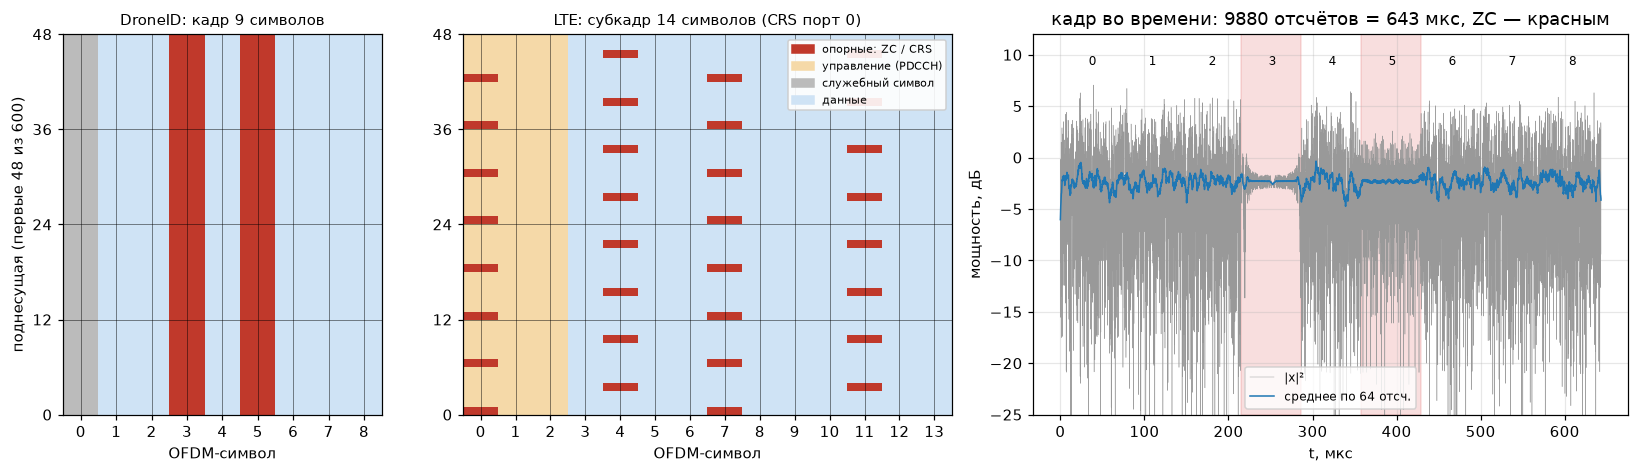

PAPR: символ данных 9.0 дБ, ZC-600 2.7 дБ, ZC-147 4.9 дБ

                                   DroneID            LTE 10 МГц
длительность, мкс                      643                  1000
доля CP                               6.7%                  6.7%
доля опорных RE                      22.2%                  4.8%
инф. бит на кадр/субкадр              1384     по CQI: 1–36 тыс.
бит на поднесущую данных              0.38            0.15 … 5.5


In [3]:
_, _, Xb = drone_tx(1, rng)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [0.75, 1.15, 1.4]})
cm = ListedColormap(["#cfe3f5", "#f5d9a8", "#c0392b", "#bbbbbb"])
G1 = np.zeros((N_SYM, 48)); G1[list(ZC_SYM)] = 2; G1[0] = 3
G2 = np.zeros((14, 48)); G2[:3] = 1
for s, sh in ((0, 0), (4, 3), (7, 0), (11, 3)):
    G2[s, sh::6] = 2
for a, M, t in ((ax[0], G1, "DroneID: кадр 9 символов"),
                (ax[1], G2, "LTE: субкадр 14 символов (CRS порт 0)")):
    a.imshow(M.T, origin="lower", aspect="auto", cmap=cm, vmin=0, vmax=3, extent=[-0.5, M.shape[0] - 0.5, -0.5, 47.5])
    a.set_xticks(range(M.shape[0])); a.set_yticks(np.arange(0, 49, 12) - 0.5, [str(v) for v in range(0, 49, 12)])
    a.grid(True, color="k", lw=0.6, alpha=0.5); a.set_xlabel("OFDM-символ"); a.set_title(t, fontsize=10)
ax[0].set_ylabel("поднесущая (первые 48 из 600)")
ax[1].legend(handles=[Patch(color=c, label=l) for c, l in [("#c0392b", "опорные: ZC / CRS"),
             ("#f5d9a8", "управление (PDCCH)"), ("#bbbbbb", "служебный символ"),
             ("#cfe3f5", "данные")]], loc="upper right", fontsize=7, framealpha=0.9)
x = ofdm_mod(Xb)[0]; t = np.arange(len(x)) / FS * 1e6
ax[2].plot(t, 10 * np.log10(np.abs(x)**2 + 1e-6), lw=0.3, color="0.6", label="|x|²")
ax[2].plot(t, 10 * np.log10(np.convolve(np.abs(x)**2, np.ones(64) / 64, "same")), "C0", lw=1, label="среднее по 64 отсч.")
for s in ZC_SYM:
    ax[2].axvspan(SYM_OFF[s] / FS * 1e6, (SYM_OFF[s] + CP_B[s] + N_FFT) / FS * 1e6, color="C3", alpha=0.15)
for s in range(N_SYM):
    ax[2].text((SYM_OFF[s] + CP_B[s] + N_FFT / 2) / FS * 1e6, 9, str(s), ha="center", fontsize=8)
ax[2].set_ylim(-25, 12); ax[2].set_xlabel("t, мкс"); ax[2].set_ylabel("мощность, дБ"); ax[2].legend(fontsize=8, loc="lower center")
ax[2].set_title(f"кадр во времени: {len(x)} отсчётов = {len(x)/FS*1e6:.0f} мкс, ZC — красным")
plt.tight_layout(); plt.show()

def papr_db(v):
    return 10 * np.log10(np.max(np.abs(v)**2) / np.mean(np.abs(v)**2))
sym = lambda s: x[SYM_OFF[s] + CP_B[s]: SYM_OFF[s] + CP_B[s] + N_FFT]
print(f"PAPR: символ данных {papr_db(sym(1)):.1f} дБ, ZC-600 {papr_db(sym(3)):.1f} дБ, ZC-147 {papr_db(sym(5)):.1f} дБ")
lte_cp = (2 * 80 + 12 * 72) / (14 * N_FFT + 2 * 80 + 12 * 72)
print(f"\n{'':32}{'DroneID':>10}{'LTE 10 МГц':>22}")
for name, d, l in [("длительность, мкс", f"{L_BURST/FS*1e6:.0f}", "1000"),
                   ("доля CP", f"{CP_B.sum()/L_BURST:.1%}", f"{lte_cp:.1%}"),
                   ("доля опорных RE", f"{2/N_SYM:.1%}", f"{8/168:.1%}"),
                   ("инф. бит на кадр/субкадр", f"{N_INFO}", "по CQI: 1–36 тыс."),
                   ("бит на поднесущую данных", f"{N_INFO/(E_BITS/2):.2f}", "0.15 … 5.5")]:
    print(f"{name:32}{d:>10}{l:>22}")

## 2. Задов–Чу: CAZAC и связь времени с частотой
$$z_u[n]=e^{-j\pi u\,n(n+1)/N_{zc}},\qquad N_{zc}=601\ (\text{простое}),\ n=0\dots600,$$
средний элемент выброшен (он попал бы на DC). Свойства, ради которых ZC стоят и в PSS/PRACH/SRS LTE, и здесь:
- **постоянная амплитуда** на всех поднесущих: канал зондируется равномерно, и LS-оценка $\hat H_k=Y_kz^*_k$ одинаково точна везде;
- **идеальная циклическая автокорреляция** и взаимная корреляция разных корней ровно $1/\sqrt{N_{zc}}$.

Главное здесь — что делает с ZC сдвиг частоты. Сдвиг на $q$ поднесущих:
$$z_u[n-q]\,z_u^*[n]=e^{\,j\pi u(2qn-q^2+q)/N_{zc}}$$
— линейная фаза по $n$, а линейная фаза по частоте — это сдвиг во времени на $(uq\bmod N_{zc})\cdot N_\text{FFT}/N_{zc}$ отсчётов. Уход частоты **неотличим** от сдвига во времени.

- Корень 600 ≡ −1 (mod 601): $z_{600}=z_1^*$, а $z_1$ — дискретный **чирп** (мгновенная частота линейна по $n$). Это тот же чирп, что в LoRa (`lora_sim`): сдвиг на 1 поднесущую = сдвиг на −1.7 отсчёта. Функция неопределённости — наклонный гребень.
- Корень 147: та же поднесущая сдвигает пик на 250 отсчётов. Гребень наклонён так круто, что сворачивается по модулю 1024 и в окно ±40 возвращается только при $\nu=\pm4$: $147\cdot4\bmod601=588\equiv-13$, то есть $\tau=\mp22$ отсчёта.
- Случайный QPSK-символ: «кнопка» в нуле и шумовой пьедестал.

Два корня с разными наклонами гребней пересекаются только в истинной точке $(\tau,\nu)=(0,0)$. Так один кадр даёт и время, и целую часть частоты (раздел 3).

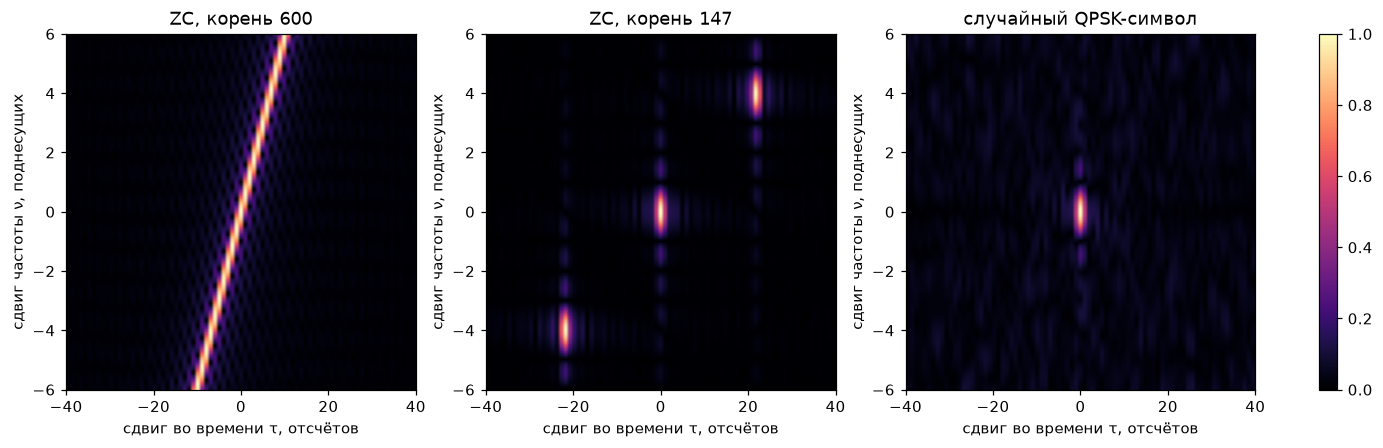

|ZC| на поднесущих: min 1.000, max 1.000
Циклическая автокорреляция ZC-600 вне главного лепестка (|τ| ≥ 3): max -18.0 дБ — это просто sinc от прямоугольного спектра 600/1024; у полной ZC-601 на сетке 601 было бы ровно 0
Взаимная корреляция 600 × 147: max -23.8 дБ; на сетке 601 было бы ровно 1/√601 = -27.8 дБ, интерполяция на 1024 отсчёта добавляет пики между узлами
Сдвиг на 1 поднесущую у корня 600 ≡ сдвиг во времени на ((u·1) mod 601)·1024/601 = 1022.3 ≡ -1.7 отсчёта
Сдвиг на 1 поднесущую у корня 147 ≡ сдвиг во времени на ((u·1) mod 601)·1024/601 = 250.5 ≡ +250.5 отсчёта


In [4]:
def tsym(vals, sc=SC_IDX):
    """один OFDM-символ без CP: значения vals на поднесущих sc"""
    return ofdm_mod(vals[None, :], cp=np.array([0]), sc=sc)

def ambiguity(x, nus, lags):
    """|χ(τ, ν)| — нормированная корреляция символа с собой, сдвинутым на τ отсчётов и на ν поднесущих"""
    n = np.arange(N_FFT); Xc = np.conj(np.fft.fft(x))
    return np.array([np.abs(np.fft.ifft(np.fft.fft(x * np.exp(2j * np.pi * nu * n / N_FFT)) * Xc))[lags % N_FFT]
                     for nu in nus]) / np.sum(np.abs(x)**2)

nus, lags = np.linspace(-6, 6, 241), np.arange(-40, 41)
syms = {"ZC, корень 600": tsym(ZC_REF[3]), "ZC, корень 147": tsym(ZC_REF[5]),
        "случайный QPSK-символ": tsym(qpsk(rng.integers(0, 2, 2 * N_SC)))}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (k, v) in zip(ax, syms.items()):
    A = ambiguity(v, nus, lags)
    im = a.imshow(A, origin="lower", aspect="auto", extent=[lags[0], lags[-1], nus[0], nus[-1]], cmap="magma", vmin=0, vmax=1)
    a.set_xlabel("сдвиг во времени τ, отсчётов"); a.set_ylabel("сдвиг частоты ν, поднесущих"); a.set_title(k)
    a.grid(False)
plt.colorbar(im, ax=ax, fraction=0.02); plt.show()

z6, z1 = ZC_REF[3], ZC_REF[5]
ac = np.abs(np.fft.ifft(np.abs(np.fft.fft(tsym(z6)))**2)) / N_SC
side = np.r_[ac[3:N_FFT - 2]].max()
print(f"|ZC| на поднесущих: min {np.abs(z6).min():.3f}, max {np.abs(z6).max():.3f}")
print(f"Циклическая автокорреляция ZC-600 вне главного лепестка (|τ| ≥ 3): max {20*np.log10(side):.1f} дБ — это просто sinc от прямоугольного спектра 600/1024; у полной ZC-601 на сетке 601 было бы ровно 0")
xc = np.abs(np.fft.ifft(np.fft.fft(tsym(z6)) * np.conj(np.fft.fft(tsym(z1))))) / N_SC
print(f"Взаимная корреляция 600 × 147: max {20*np.log10(xc.max()):.1f} дБ; на сетке 601 было бы ровно 1/√601 = {20*np.log10(1/np.sqrt(601)):.1f} дБ, интерполяция на 1024 отсчёта добавляет пики между узлами")
for u in (600, 147):
    print(f"Сдвиг на 1 поднесущую у корня {u} ≡ сдвиг во времени на ((u·1) mod 601)·1024/601 = {((u * 1) % 601) * 1024 / 601:.1f} ≡ {(((u % 601) * 1024 / 601 + 512) % 1024) - 512:+.1f} отсчёта")

### Обнаружение: ZC-600 против PSS LTE
Корреляционный обнаружитель: $T=\max_{\tau<W}|c(\tau)|^2/(N_0N_{sc})$, $c(\tau)=\sum_n r[n+\tau]\,s^*[n]$. Без сигнала на каждой задержке $T$ экспоненциальна, отсюда порог $\eta=-\ln\!\big(1-(1-P_\text{FA})^{1/W}\big)$. С сигналом на верной задержке $2T\sim\chi'^2_2(2N_{sc}\,\text{SNR})$, поэтому
$$P_D=Q_1\!\big(\sqrt{2N_{sc}\text{SNR}},\ \sqrt{2\eta}\big).$$
При одинаковом SNR на поднесущую 600 поднесущих дают на $10\lg(600/62)=9.9$ дБ больше энергии, чем PSS. Если же вся мощность передатчика сосредоточена в 62 поднесущих, энергии равны и выигрыш исчезает. Широкополосный ZC выигрывает тогда в другом: разрешение по времени $\sim1/9$ МГц ≈ 110 нс вместо ~1 мкс и частотное разнесение в многолучевом канале. В LTE PSS делит мощность базовой станции со всей несущей, поэтому сравнение «на поднесущую» — честное.

DroneID ZC-600 (600 подн.): ложные тревоги 0.0010 (цель 0.001); P_D = 0.9 при SNR ≈ -15.1 дБ


LTE PSS (62 подн.)        : ложные тревоги 0.0007 (цель 0.001); P_D = 0.9 при SNR ≈ -5.3 дБ


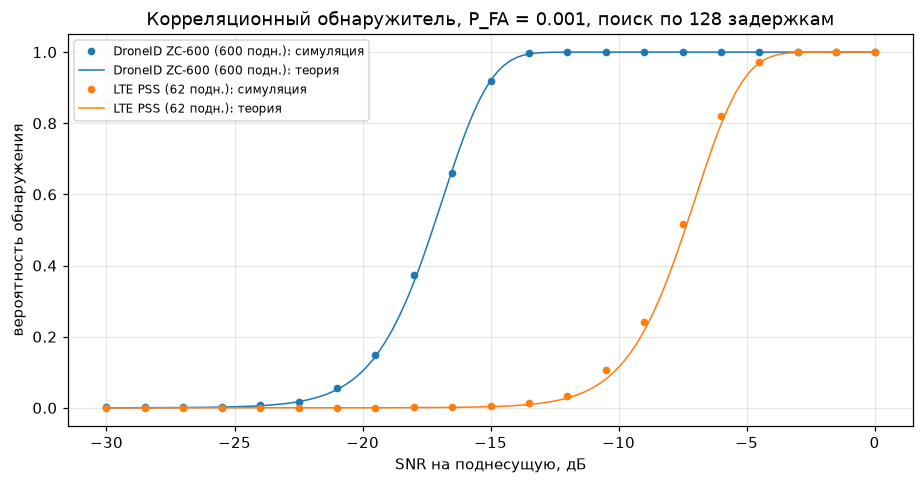

Разница = 10·lg(600/62) = 9.9 дБ: энергия опорного символа пропорциональна числу поднесущих


In [5]:
# Обнаружение: ZC-600 DroneID против PSS LTE (ZC-63, корень 25, 62 поднесущие) при одинаковом SNR на поднесущую
n63 = np.arange(63)
PSS = np.delete(np.exp(-1j * np.pi * 25 * n63 * (n63 + 1) / 63), 31)
SC_PSS = np.r_[-31:0, 1:32]
refs = {"DroneID ZC-600 (600 подн.)": (tsym(ZC_REF[3]), N_SC), "LTE PSS (62 подн.)": (tsym(PSS, SC_PSS), 62)}
W, PFA, T = 128, 1e-3, 3000                       # окно поиска по времени, вероятность ложной тревоги, испытаний
eta = -np.log(1 - (1 - PFA) ** (1 / W))           # порог на |c|²/(N0·Nsc): max из W экспонент

def detect(s, nsc, snr_db, present):
    n0 = 10 ** (-snr_db / 10)
    tau = rng.integers(0, W, T)
    r = np.sqrt(n0) * crandn((T, N_FFT), rng)
    if present:
        r += np.stack([np.roll(s, k) for k in tau])
    c = np.fft.ifft(np.fft.fft(r, axis=1) * np.conj(np.fft.fft(s)), axis=1)[:, :W]
    return (np.abs(c)**2 / (n0 * nsc)).max(1) > eta

snrs = np.arange(-30, 1, 1.5)
fig, a = plt.subplots(figsize=(8.5, 4.5))
for i, (k, (s, nsc)) in enumerate(refs.items()):
    pd = [detect(s, nsc, v, True).mean() for v in snrs]
    a.plot(snrs, pd, f"C{i}o", ms=4, label=f"{k}: симуляция")
    sg = np.linspace(snrs[0], snrs[-1], 200)
    a.plot(sg, ncx2.sf(2 * eta, 2, 2 * nsc * 10 ** (sg / 10)), f"C{i}-", lw=1, label=f"{k}: теория")
    print(f"{k:26}: ложные тревоги {detect(s, nsc, 0, False).mean():.4f} (цель {PFA}); "
          f"P_D = 0.9 при SNR ≈ {sg[np.argmax(ncx2.sf(2*eta, 2, 2*nsc*10**(sg/10)) > 0.9)]:.1f} дБ")
a.set_xlabel("SNR на поднесущую, дБ"); a.set_ylabel("вероятность обнаружения"); a.legend(fontsize=8)
a.set_title(f"Корреляционный обнаружитель, P_FA = {PFA}, поиск по {W} задержкам")
plt.tight_layout(); plt.show()
print(f"Разница = 10·lg(600/62) = {10*np.log10(600/62):.1f} дБ: энергия опорного символа пропорциональна числу поднесущих")

## 3. Синхронизация с нуля: время, дробный и целый уход частоты
В LTE телефон подстраивает свой генератор под базовую станцию (её точность ±0.05 ppm) и дальше только следит за мелким остатком. У дрона и пульта два дешёвых кварца по 10–20 ppm: на 2.44 ГГц это десятки килогерц, то есть несколько поднесущих, плюс доплер (20 м/с на 5.8 ГГц — 390 Гц). И так каждый кадр. Приёмник (как у `proto17` и в NDSS-статье) работает в три шага:

**1. CP → время и дробный уход.** Уход $\varepsilon$ (в поднесущих) поворачивает копию CP относительно хвоста символа на $e^{j2\pi\varepsilon}$:
$$\Gamma(\theta)=\sum_s\sum_{n<N_{cp,s}}r^*[\theta+o_s+n]\,r[\theta+o_s+n+N],\qquad\hat\theta=\arg\max\frac{|\Gamma|}{E},\quad\hat\varepsilon=\frac{\angle\Gamma(\hat\theta)}{2\pi}\in\pm\tfrac12 .$$
Сумма идёт по всем $L_{cp}=664$ отсчётам CP. При SNR на отсчёт $\rho=\text{SNR}\cdot600/1024$
$$\sigma_\varepsilon\approx\frac1{2\pi}\sqrt{\frac{1/\rho+1/(2\rho^2)}{L_{cp}}}.$$

**2. ZC → целый уход $q$.** Для каждой гипотезы $q$ — оценка импульсной характеристики $h_q=\text{IFFT}\big(Y[k+q]\,z^*[k]\big)$, пик ищется в окне ±24 отсчёта около найденного начала. По разделу 2 у ZC-600 соседние гипотезы дают такой же пик, смещённый всего на 1.7 отсчёта. Различает их только потеря $|q|$ краевых поднесущих, поэтому один этот корень ошибается даже на высоком SNR. ZC-147 уводит неверные гипотезы за пределы окна, кроме разницы ровно в 4 поднесущие (пик на ∓22 отсчёта, внутри окна ±24): отсюда его ~5 % ошибок. Гребни двух корней пересекаются только в истинной точке, и произведение $|h_q|$ по обоим символам однозначно.

**3. Фаза между ZC → точный уход.** Символы 3 и 5 разнесены на $2(N+N_{cp})$ отсчётов: $\varphi=\tfrac12\angle\sum_kH_{5,k}H^*_{3,k}$. Ошибка усредняется по 600 поднесущим, а база в 2.1 раза длиннее, чем у CP, — точнее на ~10 дБ. Но однозначность только ±3.5 кГц, поэтому CP идёт первым.

На низком SNR ошибки CP выше формулы: это пороговый эффект, фаза иногда перескакивает. Формула — асимптотика высокого SNR.

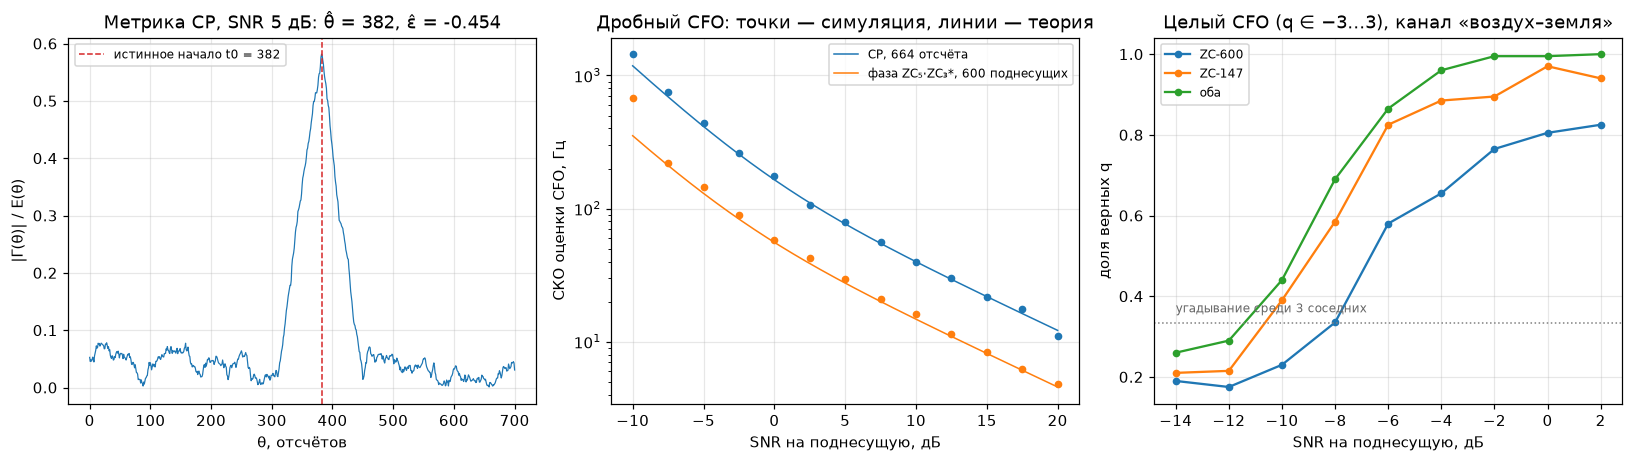

SNR -10.0 дБ: СКО CFO по CP  1446.3 Гц, по ZC  677.3 Гц (теория  1181.7 /  352.7)
SNR   0.0 дБ: СКО CFO по CP   177.1 Гц, по ZC   58.0 Гц (теория   164.8 /   55.8)
SNR  10.0 дБ: СКО CFO по CP    39.8 Гц, по ZC   16.2 Гц (теория    39.9 /   14.8)
SNR  20.0 дБ: СКО CFO по CP    11.0 Гц, по ZC    4.8 Гц (теория    12.2 /    4.6)
Однозначность: CP — ±7.5 кГц, фаза между ZC-символами (2 символа) — ±3.5 кГц, целый поиск по ZC — ±60 кГц (Q = 4); кварц 20 ppm на 2.44 ГГц — до 49 кГц


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
_, _, X = drone_tx(1, rng)
y, t0 = air(X, "a2g", SNR_DB, rng)
th, eps, M = cp_sync(y)
ax[0].plot(np.arange(M.shape[-1]), M[0], lw=0.8)
ax[0].axvline(t0[0], color="C3", ls="--", lw=1, label=f"истинное начало t0 = {t0[0]}")
ax[0].set_xlabel("θ, отсчётов"); ax[0].set_ylabel("|Γ(θ)| / E(θ)"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Метрика CP, SNR {SNR_DB} дБ: θ̂ = {th[0]}, ε̂ = {eps[0]:+.3f}")

# точность дробного CFO: CP против фазы между ZC-символами (AWGN, известное начало)
snrs = np.arange(-10, 21, 2.5); B = 400
r_cp, r_zc = [], []
for v in snrs:
    _, _, X = drone_tx(B, rng)
    eps_t = rng.uniform(-0.2, 0.2, B)
    y, t0 = air(X, "awgn", v, rng, cfo_hz=eps_t * DF)
    _, _, M = cp_sync(y)
    p = np.conj(y[:, :-N_FFT]) * y[:, N_FFT:]
    G = sum(p[np.arange(B)[:, None], t0[:, None] + o + np.arange(c)].sum(1) for o, c in zip(SYM_OFF, CP_B))
    r_cp.append(np.sqrt(np.mean((np.angle(G) / (2 * np.pi) - eps_t)**2)))
    _, phi, _, _ = zc_channel(ofdm_demod(y, t0), keep=None)
    r_zc.append(np.sqrt(np.mean((phi * N_FFT / (2 * np.pi * (N_FFT + 72)) - eps_t)**2)))
sg = np.linspace(snrs[0], snrs[-1], 200); g = 10 ** (sg / 10); rho = g * N_SC / N_FFT; n0 = 1 / g
th_cp = np.sqrt((1 / rho + 1 / (2 * rho**2)) / CP_B.sum()) / (2 * np.pi)
th_zc = np.sqrt((2 * n0 + n0**2) / (2 * N_SC)) / (2 * np.pi * 2 * (N_FFT + 72) / N_FFT)
for i, (r, th_, lab) in enumerate([(r_cp, th_cp, "CP, 664 отсчёта"), (r_zc, th_zc, "фаза ZC₅·ZC₃*, 600 поднесущих")]):
    ax[1].semilogy(snrs, np.array(r) * DF, f"C{i}o", ms=4)
    ax[1].semilogy(sg, th_ * DF, f"C{i}-", lw=1, label=lab)
ax[1].set_xlabel("SNR на поднесущую, дБ"); ax[1].set_ylabel("СКО оценки CFO, Гц")
ax[1].legend(fontsize=8); ax[1].set_title("Дробный CFO: точки — симуляция, линии — теория")

# целый CFO: один ZC против двух
snrs2 = np.arange(-14, 3, 2); B = 200
res = {k: [] for k in ("ZC-600", "ZC-147", "оба")}
for v in snrs2:
    _, _, X = drone_tx(B, rng)
    qt = rng.integers(-3, 4, B)
    y, t0 = air(X, "a2g", v, rng, cfo_hz=(qt + rng.uniform(-0.4, 0.4, B)) * DF)
    th, eps, _ = cp_sync(y)
    y = y * np.exp(-2j * np.pi * eps[:, None] * np.arange(y.shape[1]) / N_FFT)
    Yf = ofdm_demod(y, np.maximum(th - 6, 0), full=True)
    for k, s in zip(res, ((3,), (5,), (3, 5))):
        res[k].append(np.mean(int_cfo(Yf, s)[0] == qt))
for i, (k, r) in enumerate(res.items()):
    ax[2].plot(snrs2, r, f"C{i}o-", ms=4, label=k)
ax[2].axhline(1 / 3, color="0.5", ls=":", lw=1)
ax[2].text(snrs2[0], 0.36, "угадывание среди 3 соседних", fontsize=8, color="0.4")
ax[2].set_xlabel("SNR на поднесущую, дБ"); ax[2].set_ylabel("доля верных q"); ax[2].legend(fontsize=8)
ax[2].set_title("Целый CFO (q ∈ −3…3), канал «воздух–земля»")
plt.tight_layout(); plt.show()
for v, a, b in zip(snrs, r_cp, r_zc):
    if v in (-10, 0, 10, 20):
        print(f"SNR {v:5.1f} дБ: СКО CFO по CP {a*DF:7.1f} Гц, по ZC {b*DF:6.1f} Гц "
              f"(теория {np.interp(v, sg, th_cp)*DF:7.1f} / {np.interp(v, sg, th_zc)*DF:6.1f})")
print(f"Однозначность: CP — ±{DF/2/1e3:.1f} кГц, фаза между ZC-символами (2 символа) — ±{DF*N_FFT/(4*(N_FFT+72))/1e3:.1f} кГц, "
      f"целый поиск по ZC — ±{4*DF/1e3:.0f} кГц (Q = 4); кварц 20 ppm на {FC_GHZ} ГГц — до {20e-6*FC_GHZ*1e9/1e3:.0f} кГц")

## 4. Канал «воздух–земля»: прямая видимость вместо многолучёвости
Модели LTE (EPA/EVA/ETU) — релеевские: прямой видимости нет, много отражателей, $\tau_\text{rms}$ — сотни наносекунд. Дрон на высоте 100+ м видит пульт напрямую. Сигнал — это прямой луч, отражение от земли и слабое диффузное рассеяние, то есть канал **Райса** с $K=P_\text{LoS}/P_\text{diff}$. Прямой и отражённый лучи разнесены на $\Delta\tau=2h_th_r/(cd)$ — около 1 нс на 1 км, в пределах одного отсчёта. Поэтому вместе они дают одну специфическую составляющую, амплитуда которой зависит от дальности (раздел 7).

Для QPSK с MRC по $L$ антеннам — формула Крейга через производящую функцию моментов (MGF) SNR:
$$P_b=\frac1\pi\int_0^{\pi/2}M_\gamma\!\Big(-\frac{1}{2\sin^2\theta}\Big)^{L}d\theta,\qquad M_\gamma(s)=\frac{1+K}{1+K-s\bar\gamma}\exp\frac{Ks\bar\gamma}{1+K-s\bar\gamma}.$$
$K=0$ — Рэлей ($P_b\propto1/\bar\gamma$), $K\to\infty$ — AWGN.

Слева видно, чем «воздух–земля» отличается от EVA: $|H(f)|$ почти плоская на все 9 МГц ($B_c\approx10$ МГц против 0.56). Это и плюс, и минус: глубоких провалов на отдельных поднесущих нет, но если кадр замирает, то **весь целиком**, и частотного разнесения, на котором стоит LTE, нет. Выигрыш приходится брать из $K$ (держать прямую видимость) и из антенн: в O3 на пульте 4 приёмника. Справа: с MRC на 4 антенны даже в Рэлее BER лучше, чем у одной антенны в AWGN: выигрыш решётки 6 дБ перекрывает запас на замирания.

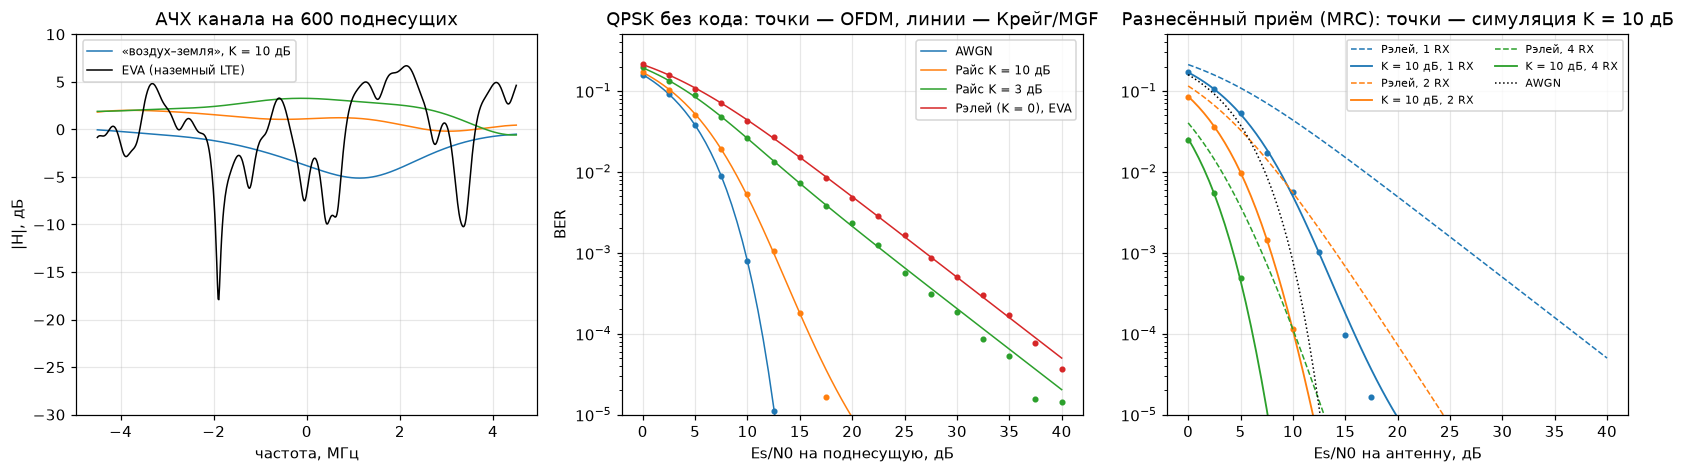

a2g : τ_rms =    21 нс, B_c ≈ 1/(5τ_rms) =  9.61 МГц
eva : τ_rms =   357 нс, B_c ≈ 1/(5τ_rms) =  0.56 МГц
BER 1e-3, Райс K = 10 дБ          : запас на замирания  +2.5 дБ к AWGN; с MRC на 4 антенны  -5.5 дБ (SNR на антенну)
BER 1e-3, Райс K = 3 дБ           : запас на замирания +13.5 дБ к AWGN; с MRC на 4 антенны  -4.0 дБ (SNR на антенну)
BER 1e-3, Рэлей (K = 0), EVA      : запас на замирания +17.0 дБ к AWGN; с MRC на 4 антенны  -2.5 дБ (SNR на антенну)


In [7]:
def ber_qpsk(snr_db, K_db=None, L=1):
    """QPSK, когерентный приём, MRC по L ветвям. Формула Крейга: Pb = (1/π)∫₀^{π/2} M_γ(−1/(2 sin²θ))^L dθ,
    M_γ(s) = (1+K)/(1+K−sγ̄)·exp(Ksγ̄/(1+K−sγ̄)) — MGF райсовского SNR. K_db=None — AWGN, K = 0 (−inf дБ) — Рэлей."""
    g = 10 ** (np.asarray(snr_db, float) / 10)
    if K_db is None:
        return 0.5 * erfc(np.sqrt(L * g / 2))
    K = 10 ** (K_db / 10)
    def pb(gb):
        mgf = lambda s: (1 + K) / (1 + K - s * gb) * np.exp(K * s * gb / (1 + K - s * gb))
        return quad(lambda t: mgf(-1 / (2 * np.sin(t)**2)) ** L, 0, np.pi / 2)[0] / np.pi
    return np.array([pb(v) for v in np.atleast_1d(g)])

def tau_rms_taps(kind, K_db=K_RICE_DB):
    if kind == "eva":
        t = EVA[0]; p = 10 ** (np.array(EVA[1]) / 10)
    else:
        K = 10 ** (K_db / 10); t = np.arange(6) / FS
        p = np.exp(-np.arange(6.0)); p = p / p.sum() / (K + 1); p[0] += K / (K + 1)
    p = p / p.sum()
    return np.sqrt((p * t**2).sum() - (p * t).sum()**2)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
f_sc = SC_IDX * DF / 1e6
for i in range(3):
    g, d = taps("a2g", np.random.default_rng(20 + i))
    ax[0].plot(f_sc, 20 * np.log10(np.abs(freq_resp(g, d))), f"C{i}", lw=1, label=f"«воздух–земля», K = {K_RICE_DB} дБ" if i == 0 else None)
g, d = taps("eva", np.random.default_rng(5))
ax[0].plot(f_sc, 20 * np.log10(np.abs(freq_resp(g, d))), "k", lw=1, label="EVA (наземный LTE)")
ax[0].set_ylim(-30, 10); ax[0].set_xlabel("частота, МГц"); ax[0].set_ylabel("|H|, дБ"); ax[0].legend(fontsize=8)
ax[0].set_title("АЧХ канала на 600 поднесущих")

snrs = np.arange(0, 41, 2.5); sg = np.linspace(0, 40, 81)
def sim_ber(kind, snr_db, L=1, B=1500, K_db=K_RICE_DB):
    """плоский канал на каждой поднесущей (H_k из модели taps), MRC по L независимым антеннам"""
    b = rng.integers(0, 2, (B, 2 * N_SC)); s = qpsk(b); n0 = 10 ** (-snr_db / 10)
    num = den = 0
    for _ in range(L):
        g, d = taps(kind, rng, (B,), K_db=K_db)
        H = freq_resp(g, d); y = H * s + np.sqrt(n0) * crandn(s.shape, rng)
        num = num + np.conj(H) * y; den = den + np.abs(H)**2
    return np.mean((qpsk_llr(num / den, 1.0) < 0) != b)
curves = [(None, "awgn", "AWGN"), (K_RICE_DB, "a2g", f"Райс K = {K_RICE_DB} дБ"), (3, "a2g", "Райс K = 3 дБ"),
          (-np.inf, "eva", "Рэлей (K = 0), EVA")]
for i, (K, kind, lab) in enumerate(curves):
    ax[1].semilogy(sg, ber_qpsk(sg, K), f"C{i}-", lw=1, label=lab)
    meas = [sim_ber(kind, v, K_db=K if K is not None else 0) for v in snrs]
    ax[1].semilogy(snrs, np.maximum(meas, 1e-9), f"C{i}o", ms=3)
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlabel("Es/N0 на поднесущую, дБ"); ax[1].set_ylabel("BER"); ax[1].legend(fontsize=8)
ax[1].set_title("QPSK без кода: точки — OFDM, линии — Крейг/MGF")
for j, L in enumerate((1, 2, 4)):
    ax[2].semilogy(sg, ber_qpsk(sg, -np.inf, L), f"C{j}--", lw=1, label=f"Рэлей, {L} RX")
    ax[2].semilogy(sg, ber_qpsk(sg, K_RICE_DB, L), f"C{j}-", lw=1.2, label=f"K = {K_RICE_DB} дБ, {L} RX")
    ax[2].semilogy(snrs, np.maximum([sim_ber("a2g", v, L, B=600) for v in snrs], 1e-9), f"C{j}o", ms=3)
ax[2].semilogy(sg, ber_qpsk(sg), "k:", lw=1, label="AWGN")
ax[2].set_ylim(1e-5, 0.5); ax[2].set_xlabel("Es/N0 на антенну, дБ"); ax[2].legend(fontsize=7, ncol=2)
ax[2].set_title("Разнесённый приём (MRC): точки — симуляция K = 10 дБ")
plt.tight_layout(); plt.show()

for k in ("a2g", "eva"):
    tr = tau_rms_taps(k)
    print(f"{k:4}: τ_rms = {tr*1e9:5.0f} нс, B_c ≈ 1/(5τ_rms) = {1/(5*tr)/1e6:5.2f} МГц")
thr = lambda f: sg[np.argmax(f < 1e-3)]
base = thr(ber_qpsk(sg))
for K, _, lab in curves[1:]:
    print(f"BER 1e-3, {lab:24}: запас на замирания {thr(ber_qpsk(sg, K)) - base:+5.1f} дБ к AWGN; с MRC на 4 антенны "
          f"{thr(ber_qpsk(sg, K, 4)) - base:+5.1f} дБ (SNR на антенну)")

## 5. Оценка канала без пилотов в данных
В кадре нет CRS: канал берут из двух ZC-символов. LS-оценка $\hat H_k=Y_kz_k^*$ есть на **каждой** из 600 поднесущих, так что интерполяция по частоте, как у CRS LTE (каждая 6-я поднесущая), не нужна. По времени между ZC-символами набегает фаза $\varphi=2\pi\,\delta f\,(N+N_{cp})/f_s$ на символ от остаточного ухода $\delta f$. Если взять $H$ только из символа 3, созвездие поворачивается тем сильнее, чем дальше символ (в `proto17` это «walking phase»). Модель $\hat H_s=\bar H\,e^{j\varphi(s-4)}$ по двум ZC это убирает.

Шум оценки: у каждой LS-оценки дисперсия ошибки $N_0$, у среднего двух — $N_0/2$, так что после эквалайзера эффективный шум ≈ $1.5N_0$ (пунктир на графике EVM). На SNR ≈ 0 дБ, где работает этот код, этого много: деление на шумную $\hat H$ разрушает LLR. Помогает то, что ZC занимает **всю** полосу. Импульсная характеристика короткая (≤ CP = 72 отсчёта ≈ 42 отсчёта 600-точечной IFFT), а шум размазан по всем 600 отсчётам. Достаточно сделать IFFT, оставить окно 52 отсчёта и сделать FFT обратно, и шум упадёт в $600/52$ раз (−10.6 дБ). С разреженными CRS так не сделать: там сначала нужна интерполяция.

У окна есть пол. 600 поднесущих из 1024 — не период, и фаза по краям полосы «рвётся»: утечка даёт ошибку ~−20 дБ при любом SNR. На высоком SNR сырой LS лучше. Реальные приёмники используют MMSE или мягкие окна, нам на SNR ≈ 0 дБ хватает и такого.

Цена такого подхода — 22 % ресурса на опорные против 4.8 % у LTE: длинный поток выгодно оценивать по редким пилотам, одиночный кадр — по плотным.

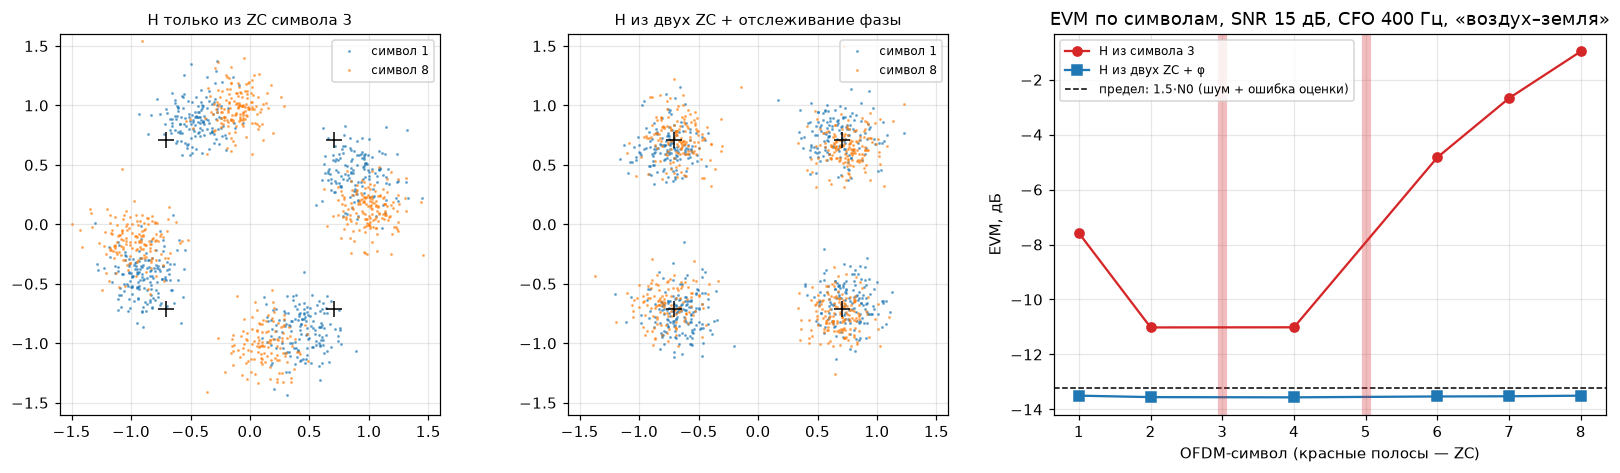

Набег фазы за символ: оценка 10.31°, теория 360°·400·(1024+72)/f_s = 10.28°

MSE оценки H по ZC (CFO скорректирован, «воздух–земля» и EVA):


  a2g  SNR  -5 дБ: LS    2.1 (теория N0/2    2.0), LS + DFT-окно   -8.1 (теория N0/2·52/600   -8.6) дБ


  a2g  SNR   0 дБ: LS   -3.0 (теория N0/2   -3.0), LS + DFT-окно  -12.6 (теория N0/2·52/600  -13.6) дБ


  a2g  SNR  10 дБ: LS  -13.0 (теория N0/2  -13.0), LS + DFT-окно  -18.8 (теория N0/2·52/600  -23.6) дБ


  a2g  SNR  20 дБ: LS  -23.0 (теория N0/2  -23.0), LS + DFT-окно  -20.2 (теория N0/2·52/600  -33.6) дБ


  eva  SNR  -5 дБ: LS    2.1 (теория N0/2    2.0), LS + DFT-окно   -8.2 (теория N0/2·52/600   -8.6) дБ


  eva  SNR   0 дБ: LS   -2.9 (теория N0/2   -3.0), LS + DFT-окно  -12.8 (теория N0/2·52/600  -13.6) дБ


  eva  SNR  10 дБ: LS  -13.0 (теория N0/2  -13.0), LS + DFT-окно  -19.7 (теория N0/2·52/600  -23.6) дБ


  eva  SNR  20 дБ: LS  -23.0 (теория N0/2  -23.0), LS + DFT-окно  -21.7 (теория N0/2·52/600  -33.6) дБ


In [8]:
snr5 = SNR_DB + 10
_, e5, X = drone_tx(300, rng)
y, t0 = air(X, "a2g", snr5, rng, cfo_hz=400.0)          # остаточный CFO 400 Гц: «забыли» скорректировать
Y = ofdm_demod(y, t0)
Hs, phi, n0e, H3 = zc_channel(Y)
Xd = X[:, DATA_SYM]
Z_hold = Y[:, DATA_SYM] / H3[:, None, :]                  # H из символа 3 для всех
Z_trk = Y[:, DATA_SYM] / Hs                               # H из двух ZC + набег фазы
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for a, Z, t in ((ax[0], Z_hold, "H только из ZC символа 3"), (ax[1], Z_trk, "H из двух ZC + отслеживание фазы")):
    for j, s in ((0, 1), (5, 8)):
        a.plot(Z[0, j].real, Z[0, j].imag, ".", ms=2, alpha=0.5, label=f"символ {s}")
    a.plot([-0.71, 0.71, -0.71, 0.71], [-0.71, -0.71, 0.71, 0.71], "k+", ms=10)
    a.set_aspect("equal"); a.set_xlim(-1.6, 1.6); a.set_ylim(-1.6, 1.6); a.legend(fontsize=8, loc="upper right"); a.set_title(t, fontsize=10)
evm = lambda Z: 10 * np.log10(np.mean(np.abs(Z - Xd)**2, axis=(0, 2)))
ax[2].plot(DATA_SYM, evm(Z_hold), "C3o-", label="H из символа 3")
ax[2].plot(DATA_SYM, evm(Z_trk), "C0s-", label="H из двух ZC + φ")
ax[2].axhline(10 * np.log10(1.5 * 10 ** (-snr5 / 10)), color="k", ls="--", lw=1, label="предел: 1.5·N0 (шум + ошибка оценки)")
for s in ZC_SYM:
    ax[2].axvline(s, color="C3", alpha=0.3, lw=6)
ax[2].set_xlabel("OFDM-символ (красные полосы — ZC)"); ax[2].set_ylabel("EVM, дБ"); ax[2].legend(fontsize=8)
ax[2].set_title(f"EVM по символам, SNR {snr5} дБ, CFO 400 Гц, «воздух–земля»")
plt.tight_layout(); plt.show()
print(f"Набег фазы за символ: оценка {np.degrees(np.median(phi)):.2f}°, теория 360°·400·(1024+72)/f_s = {360*400*(N_FFT+72)/FS:.2f}°")

print("\nMSE оценки H по ZC (CFO скорректирован, «воздух–земля» и EVA):")
for kind in ("a2g", "eva"):
    for v in (-5, 0, 10, 20):
        _, _, X = drone_tx(200, rng)
        y, t0, H = air(X, kind, v, rng, cfo_hz=0.0, ret_h=True)
        Y = ofdm_demod(y, t0 - 6)
        H = H * np.exp(-2j * np.pi * SC_IDX * 6 / N_FFT)                # окно FFT на 6 отсчётов раньше, как в приёмнике
        m = [10 * np.log10(np.mean(np.abs(zc_channel(Y, k)[0] - H[:, None, :])**2)) for k in (None, KEEP)]
        n0 = 10 ** (-v / 10)
        print(f"  {kind:4} SNR {v:3d} дБ: LS {m[0]:6.1f} (теория N0/2 {10*np.log10(n0/2):6.1f}), "
              f"LS + DFT-окно {m[1]:6.1f} (теория N0/2·{sum(KEEP)}/{N_SC} {10*np.log10(n0/2*sum(KEEP)/N_SC):6.1f}) дБ")


## 6. Код: турбокод LTE, кольцевой буфер и повторы
Цепочка (36.212, восстановлена по прошивке): 1384 бита + CRC24A → $K=1408$ → турбокод LTE $R=1/3$ (подробно — `turbo_sim`) → три потока по $K+4=1412$ бит → **подблочный перемежитель** (32 столбца, перестановка столбцов из стандарта) → **кольцевой буфер** $w=[v_0,\ v_1/v_2\text{ через один}]$ → чтение $E=7200$ бит с позиции $k_0=2R_\text{sb}$ по кругу.

4236 бит не хватает на 7200, поэтому буфер проходится 1.7 раза: 94 % систематических и 58 % проверочных бит уходят **дважды**. Слева видно, как читается буфер: сначала систематика (перемешанная подблочным перемежителем), потом обе проверки через одну, потом второй круг. Приёмник просто складывает LLR повторов. Это chase combining внутри одного кадра, +$10\lg(7200/4236)=2.3$ дБ энергии. Итог: $R=0.192$, 0.384 бит на поднесущую, предел Шеннона для QPSK −5.1 дБ. Так устроен и PBCH в LTE: широковещательный сигнал, который должен ловиться далеко, кодируют с большим запасом и повторами.

Кривые справа (кадр считается принятым, если сошёлся CRC):
- **идеальный приём** — LLR прямо из AWGN, без OFDM и синхронизации: в ~1.7 дБ от Шеннона, как и положено турбокоду при $K\approx1400$;
- **полный приёмник, AWGN** — всё из разделов 3 и 5 (неизвестное начало, уход 23 кГц, оценка по ZC): потеря ~0.5 дБ;
- **«воздух–земля»** — кривая пологая: весь кадр замирает вместе (раздел 4), и код не может «занять» энергию у хороших поднесущих. Крутизну даёт только $K$: при 10 дБ провалы неглубокие, и ~2.4 дБ на декаду;
- **EVA** — на 1.5–2 дБ правее, но с почти тем же наклоном. Из 9 лучей EVA на сетке 65 нс сильных независимых около четырёх, так что частотное разнесение (раздел 8 `lte_sim`) — порядка 4. Прямая видимость с $K=10$ дБ даёт сопоставимую «эффективную» крутизну без всякого разнесения. Если прямую видимость потерять (`K_RICE_DB = 0`), плоский канал проигрывает EVA много дБ.

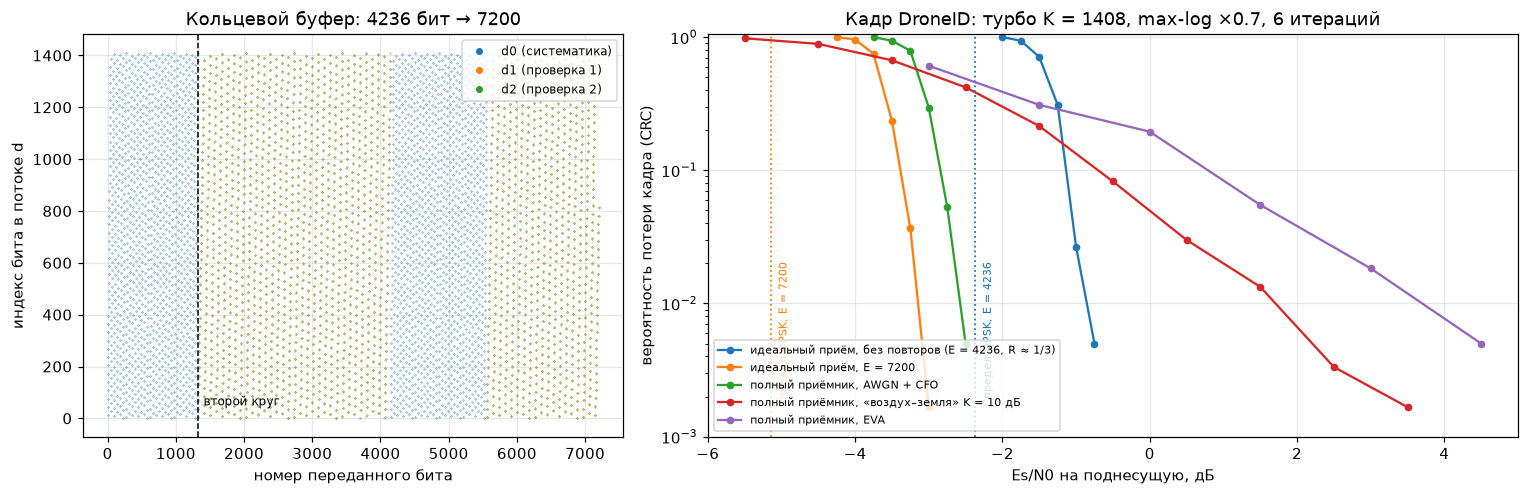

d0: передано 1 раз 6%, 2 раза 94%
d1: передано 1 раз 42%, 2 раза 58%
d2: передано 1 раз 42%, 2 раза 58%
Предел Шеннона для QPSK: -5.14 дБ (E = 7200), -2.37 дБ (E = 4236)
                                                               BLER 10 %  BLER 1 %
идеальный приём, без повторов (E = 4236, R ≈ 1/3)                -1.13 дБ  -0.85 дБ
идеальный приём, E = 7200                                        -3.39 дБ  -3.14 дБ
полный приёмник, AWGN + CFO                                      -2.84 дБ  -2.57 дБ
полный приёмник, «воздух–земля» K = 10 дБ                        -0.70 дБ   1.71 дБ
полный приёмник, EVA                                              0.79 дБ   3.70 дБ
Повторы дают 2.3 дБ (ровно энергетика: 10·lg(7200/4236) = 2.3 дБ); потери реального приёмника 0.5 дБ


In [9]:
def biawgn_cap(g):
    """ёмкость BPSK-AWGN, бит, при SNR g на измерение (сигнал/дисперсия шума)"""
    mu = 2 * g
    f = lambda l: np.log2(1 + np.exp(-l)) * np.exp(-(l - mu)**2 / (4 * mu)) / np.sqrt(4 * np.pi * mu)
    return 1 - quad(f, mu - 40 * np.sqrt(mu), mu + 40 * np.sqrt(mu))[0]
SNR_TAB = np.linspace(-25, 25, 401)
CAP_QPSK = np.array([2 * biawgn_cap(10 ** (v / 10)) for v in SNR_TAB])     # QPSK = два BPSK с SNR Es/N0
qpsk_limit = lambda r: np.interp(r, CAP_QPSK, SNR_TAB)

counts = np.bincount(RM_IDX, minlength=3 * D_TB).reshape(3, D_TB)
RM_R3 = rm_index(D_TB, 3 * D_TB)                                          # те же биты без повторов: R ≈ 1/3

def run_bler(snrs, mode, min_fe=30, max_frames=600, batch=100):
    """mode: 'genie' — LLR прямо из AWGN, без OFDM и синхронизации; 'genie13' — то же без повторов (E = 3D);
    'awgn' / 'a2g' / 'eva' — полный кадр через канал с CFO и неизвестным началом, полный приёмник."""
    out = []
    for v in snrs:
        fe = nf = 0; n0 = 10 ** (-v / 10)
        while fe < min_fe and nf < max_frames:
            if mode.startswith("genie"):
                rm = RM_R3 if mode == "genie13" else RM_IDX
                a = rng.integers(0, 2, (batch, N_INFO))
                c = turbo_encode_d(np.c_[a, crc24a(a)]).reshape(batch, -1)[:, rm]
                s = qpsk(c); z = s + np.sqrt(n0) * crandn(s.shape, rng)
                ah, ok = decode_e(qpsk_llr(z, n0), rm=rm)
            else:
                a, _, X = drone_tx(batch, rng)
                y, _ = air(X, mode, v, rng)
                ah, ok, _ = drone_rx(y)
            fe += np.sum(~(ok & np.all(ah == a, 1))); nf += batch
        out.append(fe / nf)
    return np.array(out)

grid = {"genie13": np.arange(-2, -0.4, 0.25), "genie": np.arange(-4.25, -2.6, 0.25), "awgn": np.arange(-3.75, -2.1, 0.25),
        "a2g": np.arange(-5.5, 3.6, 1.0), "eva": np.arange(-3, 7.6, 1.5)}
labels = {"genie13": "идеальный приём, без повторов (E = 4236, R ≈ 1/3)",
          "genie": "идеальный приём, E = 7200", "awgn": "полный приёмник, AWGN + CFO",
          "a2g": f"полный приёмник, «воздух–земля» K = {K_RICE_DB} дБ", "eva": "полный приёмник, EVA"}
bler = {k: run_bler(v, k) for k, v in grid.items()}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
pos = np.arange(E_BITS)
for i, nm in enumerate(("d0 (систематика)", "d1 (проверка 1)", "d2 (проверка 2)")):
    m = RM_IDX // D_TB == i
    ax[0].plot(pos[m], RM_IDX[m] % D_TB, ".", ms=0.6, color=f"C{i}", label=nm)
ax[0].axvline(np.argmax(np.r_[0, np.diff(RM_IDX // D_TB)] < 0), color="k", ls="--", lw=1)
ax[0].text(np.argmax(np.r_[0, np.diff(RM_IDX // D_TB)] < 0) + 80, 50, "второй круг", fontsize=8)
ax[0].set_xlabel("номер переданного бита"); ax[0].set_ylabel("индекс бита в потоке d")
ax[0].legend(fontsize=8, markerscale=12, loc="upper right"); ax[0].set_title(f"Кольцевой буфер: {3*D_TB} бит → {E_BITS}")
for i, (k, r) in enumerate(bler.items()):
    ok = r > 0
    ax[1].semilogy(grid[k][ok], r[ok], f"C{i}o-", ms=4, label=labels[k])
for r_, c, nm in ((N_INFO / (E_BITS / 2), "C1", "E = 7200"), (N_INFO / (3 * D_TB / 2), "C0", "E = 4236")):
    ax[1].axvline(qpsk_limit(r_), color=c, ls=":", lw=1.2)
    ax[1].text(qpsk_limit(r_) + 0.1, 2e-3, f"предел QPSK, {nm}", rotation=90, fontsize=7, color=c)
ax[1].set_ylim(1e-3, 1.05); ax[1].set_xlabel("Es/N0 на поднесущую, дБ"); ax[1].set_ylabel("вероятность потери кадра (CRC)")
ax[1].legend(fontsize=7.5, loc="lower left"); ax[1].set_title(f"Кадр DroneID: турбо K = {K_TB}, max-log ×0.7, {TURBO_ITERS} итераций")
plt.tight_layout(); plt.show()

def snr_at(k, target=0.1):
    r = np.maximum(bler[k], 1e-4); g = grid[k]
    j = np.argmax(r < target)
    if j == 0:
        return np.nan
    return np.interp(np.log10(target), np.log10(r[[j, j - 1]]), g[[j, j - 1]])
for i, nm in enumerate(("d0", "d1", "d2")):
    print(f"{nm}: передано 1 раз {np.mean(counts[i] == 1):.0%}, 2 раза {np.mean(counts[i] == 2):.0%}")
print(f"Предел Шеннона для QPSK: {qpsk_limit(N_INFO/(E_BITS/2)):.2f} дБ (E = 7200), {qpsk_limit(N_INFO/(3*D_TB/2)):.2f} дБ (E = 4236)")
REQ = {k: snr_at(k) for k in bler}
print(f"{'':62}{'BLER 10 %':>10}{'BLER 1 %':>10}")
for k, v in REQ.items():
    print(f"{labels[k]:62}{v:8.2f} дБ{snr_at(k, 0.01):7.2f} дБ")
print(f"Повторы дают {REQ['genie13'] - REQ['genie']:.1f} дБ (ровно энергетика: 10·lg(7200/4236) = {10*np.log10(E_BITS/(3*D_TB)):.1f} дБ); "
      f"потери реального приёмника {REQ['awgn'] - REQ['genie']:.1f} дБ")

## 7. Бюджет линии: два луча, излом и адаптация полосы
Дрон далеко и высоко, пульт у земли. Сигнал — прямой луч плюс отражение от земли с коэффициентом Френеля $\Gamma(\psi)$. Для вертикальной поляризации (антенны дрона и пульта) он стремится к −1 при скользящем падении и почти обнуляется у угла Брюстера $\arctan(1/\sqrt{\varepsilon_r})\approx14°$. Поэтому вблизи провалы мелкие, а вдали глубокие:
$$G(d)=\Big(\frac{\lambda}{4\pi}\Big)^2\Big|\frac{e^{-jkd_1}}{d_1}+\Gamma\frac{e^{-jkd_2}}{d_2}\Big|^2\ \xrightarrow{\ d\gg d_b\ }\ \frac{(h_th_r)^2}{d^4},\qquad d_b=\frac{4h_th_r}{\lambda}.$$
До точки излома $d_b$ потери как в свободном пространстве, с интерференционными провалами. После излома они растут как $d^{4}$ и от частоты не зависят: лучи гасят друг друга. Причина — первая зона Френеля (радиус ~18 м посередине 10-км трассы) упирается в землю. Отсюда совет поднимать пульт и антенны: $d_b\propto h_r$.

Мощность ограничена правилами ISM (EIRP 20 dBm по CE, до 30 dBm по FCC на 2.4 ГГц), шум равен $-174+10\lg B+NF$ dBm. При фиксированной мощности **SNR ∝ 1/B**: узкая полоса летит дальше. Поэтому OcuSync сужает полосу с дальностью (40 → 20 → 10 → 1.4 МГц) и снижает MCS. В LTE полоса несущей фиксирована, но планировщик выдаёт дальнему телефону мало RB, и на аплинке его мощность сосредоточена в них: физика та же, только решение принимает базовая станция.

Скорость считаем как $0.75\cdot B\cdot\min(\log_2(1+\text{SNR}/\Gamma),5.5)$ с зазором $\Gamma=3$ дБ (типичный для турбокодов). Порог минимального MCS — кадр DroneID из раздела 6, запас на замирания и потери 10 дБ. Кривые без запаса в 1.5–2 раза оптимистичнее заявленных DJI 8 км (CE) / 15 км (FCC) для O3. С запасом получается тот же порядок.

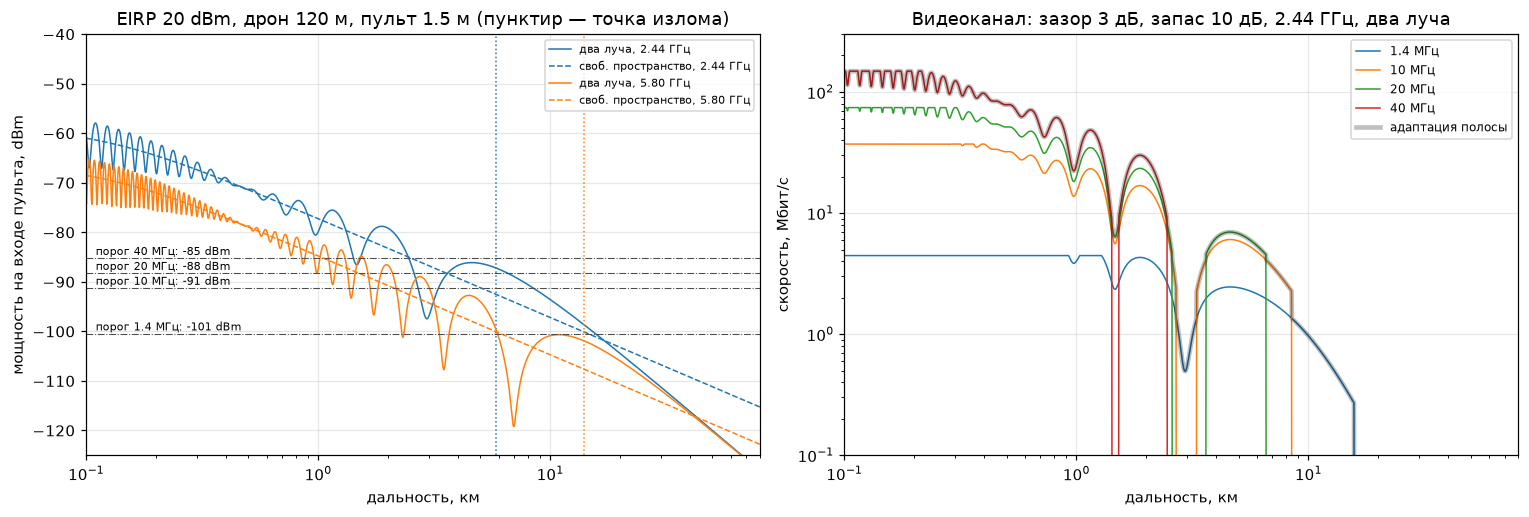

Точка излома двухлучевой модели d_b = 4·h_t·h_r/λ: 5.9 км (2.44 ГГц), 13.9 км (5.8 ГГц)
Угол Брюстера atan(1/√ε) = 14.5° — на дальности 0.47 км; Γ на 1 / 5 / 20 км: -0.35 / -0.82 / -0.95
Радиус 1-й зоны Френеля посередине трассы 10 км: 18 м — пульт на 1.5 м её не очищает

                 EIRP 20 dBm       EIRP 30 dBm
  1.4 МГц           15.7 км           28.7 км
   10 МГц            8.5 км           16.5 км
   20 МГц            6.6 км           13.6 км
   40 МГц            2.5 км           11.2 км
(запас 10 дБ; радиогоризонт 4.12·(√h_t+√h_r) = 50 км; последняя дальность, на которой минимальный MCS ещё проходит; с ростом мощности на 10 дБ дальность растёт в 10^(10/40) ≈ 1.8 раза за точкой излома, а не в √10 ≈ 3.2)


In [10]:
EPS_GROUND = 15                                              # относительная проницаемость средней почвы

def gamma_v(d, ht=H_DRONE, hr=H_RC, eps=EPS_GROUND):
    """Коэффициент отражения Френеля, вертикальная поляризация: −1 при скользящем падении, ~0 у угла Брюстера."""
    psi = np.arctan((ht + hr) / d); r = np.sqrt(eps - np.cos(psi)**2)
    return (eps * np.sin(psi) - r) / (eps * np.sin(psi) + r)

def path_gain(d, fc, two_ray=True, ht=H_DRONE, hr=H_RC):
    """Усиление трассы: свободное пространство или два луча (прямой + отражение от земли с Γ по Френелю)."""
    lam = 3e8 / fc; k = 2 * np.pi / lam
    d1 = np.sqrt(d**2 + (ht - hr)**2); d2 = np.sqrt(d**2 + (ht + hr)**2)
    if not two_ray:
        return (lam / (4 * np.pi * d1))**2
    return (lam / (4 * np.pi))**2 * np.abs(np.exp(-1j * k * d1) / d1 + gamma_v(d, ht, hr) * np.exp(-1j * k * d2) / d2)**2

noise_dbm = lambda bw: -174 + 10 * np.log10(bw) + NF_DB
SC_BW = {1.4: 72, 10: 600, 20: 1200, 40: 2400}              # занятых поднесущих по 15 кГц
REQ_DB = REQ["awgn"]                                         # порог кадра DroneID из раздела 6
GAP_DB, ETA_MAX, OVH = 3.0, 5.5, 0.75                        # зазор до Шеннона, потолок 64QAM, накладные расходы
MARGIN_DB = 10                                               # запас: замирания, поляризация, корпус, помехи
d = np.logspace(2, np.log10(80e3), 1500)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for i, f in enumerate((FC_GHZ * 1e9, 5.8e9)):
    ax[0].semilogx(d / 1e3, EIRP_DBM + G_RX_DBI + 10 * np.log10(path_gain(d, f)), f"C{i}", lw=1, label=f"два луча, {f/1e9:.2f} ГГц")
    ax[0].semilogx(d / 1e3, EIRP_DBM + G_RX_DBI + 10 * np.log10(path_gain(d, f, False)), f"C{i}--", lw=1, label=f"своб. пространство, {f/1e9:.2f} ГГц")
    db = 4 * H_DRONE * H_RC * f / 3e8
    ax[0].axvline(db / 1e3, color=f"C{i}", ls=":", lw=1)
for j, bw in enumerate(SC_BW):
    s = noise_dbm(SC_BW[bw] * DF) + REQ_DB + MARGIN_DB
    ax[0].axhline(s, color="0.3", lw=0.7, ls="-.")
    ax[0].text(0.11, s + 0.7, f"порог {bw} МГц: {s:.0f} dBm", fontsize=7)
ax[0].set_xlim(0.1, 80); ax[0].set_ylim(-125, -40); ax[0].set_xlabel("дальность, км"); ax[0].set_ylabel("мощность на входе пульта, dBm")
ax[0].legend(fontsize=7, loc="upper right"); ax[0].set_title(f"EIRP {EIRP_DBM} dBm, дрон {H_DRONE} м, пульт {H_RC} м (пунктир — точка излома)")

rates = {}
for j, bw in enumerate(SC_BW):
    B = SC_BW[bw] * DF
    snr = EIRP_DBM + G_RX_DBI + 10 * np.log10(path_gain(d, FC_GHZ * 1e9)) - noise_dbm(B) - MARGIN_DB
    eta = np.minimum(np.log2(1 + 10 ** ((snr - GAP_DB) / 10)), ETA_MAX) * (snr >= REQ_DB)
    rates[bw] = OVH * B * eta / 1e6
    ax[1].loglog(d / 1e3, np.maximum(rates[bw], 1e-3), f"C{j}", lw=1, label=f"{bw} МГц")
env = np.max(np.stack(list(rates.values())), 0)
ax[1].loglog(d / 1e3, np.maximum(env, 1e-3), color="k", lw=3, alpha=0.25, label="адаптация полосы")
ax[1].set_xlim(0.1, 80); ax[1].set_ylim(0.1, 300); ax[1].set_xlabel("дальность, км"); ax[1].set_ylabel("скорость, Мбит/с"); ax[1].legend(fontsize=8)
ax[1].set_title(f"Видеоканал: зазор {GAP_DB:.0f} дБ, запас {MARGIN_DB} дБ, {FC_GHZ} ГГц, два луча")
plt.tight_layout(); plt.show()

print(f"Точка излома двухлучевой модели d_b = 4·h_t·h_r/λ: {4*H_DRONE*H_RC*FC_GHZ*1e9/3e8/1e3:.1f} км ({FC_GHZ} ГГц), {4*H_DRONE*H_RC*5.8e9/3e8/1e3:.1f} км (5.8 ГГц)")
print(f"Угол Брюстера atan(1/√ε) = {np.degrees(np.arctan(1/np.sqrt(EPS_GROUND))):.1f}° — на дальности {(H_DRONE+H_RC)*np.sqrt(EPS_GROUND)/1e3:.2f} км; Γ на 1 / 5 / 20 км: {gamma_v(1e3):.2f} / {gamma_v(5e3):.2f} / {gamma_v(20e3):.2f}")
print(f"Радиус 1-й зоны Френеля посередине трассы 10 км: {np.sqrt(3e8/(FC_GHZ*1e9)*5e3*5e3/1e4):.0f} м — пульт на {H_RC} м её не очищает")
print(f"\n{'':10}" + "".join(f"{'EIRP ' + str(p) + ' dBm':>18}" for p in (20, 30)))
for bw in SC_BW:
    B = SC_BW[bw] * DF; line = f"{bw:>5} МГц"
    for p in (20, 30):
        ok = p + G_RX_DBI + 10 * np.log10(path_gain(d, FC_GHZ * 1e9)) - noise_dbm(B) - MARGIN_DB >= REQ_DB
        line += f"{d[np.nonzero(ok)[0].max()]/1e3:15.1f} км"
    print(line)
print(f"(запас {MARGIN_DB} дБ; радиогоризонт 4.12·(√h_t+√h_r) = {4.12*(np.sqrt(H_DRONE)+np.sqrt(H_RC)):.0f} км; последняя дальность, на которой минимальный MCS ещё проходит; с ростом мощности на 10 дБ дальность растёт в 10^(10/40) ≈ 1.8 раза за точкой излома, а не в √10 ≈ 3.2)")

## 8. ISM: соседи по эфиру и скачки частоты
У LTE свой лицензированный спектр: мешают только соседние соты той же сети, и с ними договариваются (ICIC, управление мощностью). OcuSync живёт в 2.4 ГГц вместе с Wi-Fi, Bluetooth и чужими дронами, и договориться ни с кем нельзя. Остаются **скачки частоты** (DroneID меняет частоту от кадра к кадру), **выбор канала** по измерениям эфира (в приложении DJI это график помех) и переход между 2.4 и 5.8 ГГц.

Модель: в каждом сеансе 3 сети Wi-Fi на случайных каналах 1–13, каждая занята в доле `WIFI_DUTY` кадров, помеха на 10 дБ выше шума. Дрон работает с запасом 3 дБ над порогом раздела 6. Помеха задевает только часть из 600 поднесущих, поэтому вероятность потери считается через **MIESM** — тот же метод, что в системных симуляторах LTE:
$$\gamma_\text{eff}=I^{-1}\!\Big(\frac1{N}\sum_kI(\gamma_k)\Big),$$
где $I$ — взаимная информация QPSK, а BLER берётся из кривой AWGN раздела 6. Стратегии: фиксированный случайный канал на сеанс, случайный скачок каждый кадр, адаптивный выбор (10 кадров слушаем эфир, потом берём наименее занятую позицию).

- **Средние** потери у фиксированного канала и у скачков одинаковы: по симметрии это одно и то же усреднение по каналам.
- Отличается **разброс**. Фиксированный канал либо хорош, либо попал под Wi-Fi на весь сеанс (бимодальная гистограмма). Скачки превращают долгие провалы в редкие одиночные потери, и тогда их добивает внешний код стирания или повтор: видеокадр из 4 пакетов с кодом 3-из-4 теряется заметно реже.
- **Адаптивный выбор** выигрывает на порядки: в 83.5 МГц почти всегда есть 10-МГц дыра между сетями Wi-Fi. Его кривая немонотонна: при занятости 5–20 % за 10 кадров прослушивания Wi-Fi часто не успевает «показаться», и дрон садится прямо на него. Уровень $10^{-4}$ — это просто нижний край измеренной кривой BLER, на деле потерь нет.

Активность Wi-Fi здесь независима от кадра к кадру. В жизни она пачками, и выигрыш скачков от этого только больше.

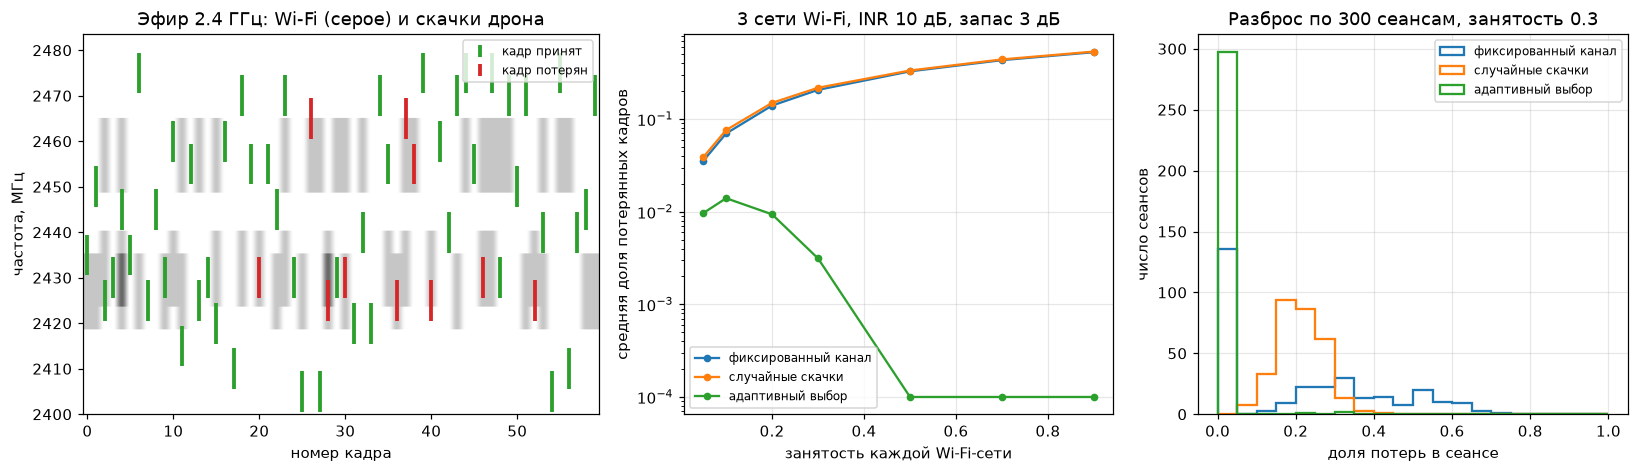

фиксированный канал   : средние потери 0.204; доля сеансов с потерями > 30 % 0.36; потеря видеокадра из 4 пакетов с кодом стирания 3-из-4 0.2549
случайные скачки      : средние потери 0.212; доля сеансов с потерями > 30 % 0.06; потеря видеокадра из 4 пакетов с кодом стирания 3-из-4 0.1993
адаптивный выбор      : средние потери 0.003; доля сеансов с потерями > 30 % 0.01; потеря видеокадра из 4 пакетов с кодом стирания 3-из-4 0.0031


In [11]:
WIFI_BW, INR_DB = 16.6e6, 10                       # занятая полоса Wi-Fi 20 МГц; помеха над шумом, когда сеть передаёт
CH = np.arange(2405, 2476, 5) * 1e6                 # 15 позиций 10-МГц канала в 2400–2483.5 МГц
WIFI_CH = 2412e6 + 5e6 * np.arange(13)             # каналы Wi-Fi 1–13
S_SESS, NB, NS = 300, 60, 10                        # сеансов, кадров в сеансе, из них на «прослушивание» эфира
OP_DB = REQ["awgn"] + 3                             # рабочая точка: 3 дБ запаса над порогом
g_awgn = grid["awgn"]; lb_awgn = np.log10(np.maximum(bler["awgn"], 1e-4))

def bler_lookup(snr_eff):
    """MIESM: эффективный SNR → BLER из кривой AWGN раздела 6"""
    return np.where(snr_eff < g_awgn[0], 1.0, np.where(snr_eff > g_awgn[-1], 1e-4, 10 ** np.interp(snr_eff, g_awgn, lb_awgn)))

def eff_snr(sinr_db):
    """MIESM: среднее по поднесущим взаимной информации QPSK → обратно в «эквивалентный AWGN SNR»"""
    mi = np.interp(sinr_db, SNR_TAB, CAP_QPSK).mean(-1)
    return np.interp(mi, CAP_QPSK, SNR_TAB)

def session_sim(duty, rng, n_wifi=3):
    """Каждый сеанс: n_wifi сетей на случайных каналах 1–13, каждая занята в доле duty кадров (независимо)."""
    fw = WIFI_CH[rng.integers(0, 13, (S_SESS, n_wifi))]
    act = rng.random((S_SESS, NB, n_wifi)) < duty
    def per(ch):                                     # ch (S, NB) → вероятность потери каждого кадра
        f = CH[ch][..., None] + SC_IDX * DF          # (S, NB, 600)
        hit = np.abs(f[..., None] - fw[:, None, None, :]) < WIFI_BW / 2
        I = 10 ** (INR_DB / 10) * np.sum(hit * act[:, :, None, :], -1)
        return bler_lookup(eff_snr(OP_DB - 10 * np.log10(1 + I)))
    fixed = np.repeat(rng.integers(0, len(CH), (S_SESS, 1)), NB, 1)
    hop = rng.integers(0, len(CH), (S_SESS, NB))
    f_all = CH[:, None] + SC_IDX * DF                 # прослушивание: средняя доля «зашумлённых» поднесущих по первым NS кадрам
    load = np.einsum("swc,sw->sc", (np.abs(f_all[None, :, :, None] - fw[:, None, None, :]) < WIFI_BW / 2).mean(2).transpose(0, 2, 1),
                     act[:, :NS].mean(1))
    adapt = np.repeat(np.argmin(load, 1)[:, None], NB, 1)
    return {k: per(c)[:, NS:] for k, c in (("фиксированный канал", fixed), ("случайные скачки", hop),
                                         ("адаптивный выбор", adapt))}, fw, act, hop

duties = np.array([0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9])
curves = {}
for dty in duties:
    for k, p in session_sim(dty, np.random.default_rng(7))[0].items():
        curves.setdefault(k, []).append(p.mean())
res, fw, act, hop = session_sim(WIFI_DUTY, np.random.default_rng(8))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.2, 1, 1]})
s0 = 0
img = np.zeros((NB, 300)); fgrid = np.linspace(2400e6, 2483.5e6, 300)
for w in range(fw.shape[1]):
    img += act[s0, :, w, None] * (np.abs(fgrid - fw[s0, w]) < WIFI_BW / 2)
ax[0].imshow(img.T, origin="lower", aspect="auto", cmap="Greys", vmin=0, vmax=3, extent=[-0.5, NB - 0.5, 2400, 2483.5])
p_hop = res["случайные скачки"][s0]
ok = np.r_[np.ones(NS, bool), rng.random(NB - NS) > p_hop]
for m, c, lab in ((ok, "C2", "кадр принят"), (~ok, "C3", "кадр потерян")):
    ax[0].errorbar(np.nonzero(m)[0], CH[hop[s0, m]] / 1e6, yerr=N_SC * DF / 2e6, fmt="none", ecolor=c, elinewidth=2.5, label=lab)
ax[0].set_xlabel("номер кадра"); ax[0].set_ylabel("частота, МГц"); ax[0].legend(fontsize=8, loc="upper right")
ax[0].set_title("Эфир 2.4 ГГц: Wi-Fi (серое) и скачки дрона"); ax[0].grid(False)
for i, (k, v) in enumerate(curves.items()):
    ax[1].semilogy(duties, v, f"C{i}o-", ms=4, label=k)
ax[1].set_xlabel("занятость каждой Wi-Fi-сети"); ax[1].set_ylabel("средняя доля потерянных кадров"); ax[1].legend(fontsize=8)
ax[1].set_title(f"3 сети Wi-Fi, INR {INR_DB} дБ, запас {OP_DB - REQ['awgn']:.0f} дБ")
bins = np.linspace(0, 1, 21)
for i, k in enumerate(res):
    ax[2].hist(res[k].mean(1), bins, histtype="step", lw=1.5, color=f"C{i}", label=k)
ax[2].set_xlabel("доля потерь в сеансе"); ax[2].set_ylabel("число сеансов"); ax[2].legend(fontsize=8)
ax[2].set_title(f"Разброс по {S_SESS} сеансам, занятость {WIFI_DUTY}")
plt.tight_layout(); plt.show()

for k, p in res.items():
    q = p[:, :48].reshape(S_SESS, 12, 4)
    fail = 1 - (np.prod(1 - q, -1) + sum(q[..., j] * np.prod(np.delete(1 - q, j, -1), -1) for j in range(4)))
    print(f"{k:22}: средние потери {p.mean():.3f}; доля сеансов с потерями > 30 % "
          f"{np.mean(p.mean(1) > 0.3):.2f}; потеря видеокадра из 4 пакетов с кодом стирания 3-из-4 {fail.mean():.4f}")

## Сравнение с LTE
| | LTE | OcuSync / DroneID |
|---|---|---|
| Задача | сотовая сеть: тысячи абонентов, мобильность, роуминг | одна линия точка–точка: дрон ↔ пульт |
| Спектр | лицензированный, помехи только свои и управляемые | ISM 2.4/5.8 ГГц, общий с Wi-Fi: скачки, выбор канала, смена диапазона |
| Нумерология | 15 кГц, 15.36 МГц / 1024, CP 72–80 | **та же** (для 10 МГц) |
| Синхронизация | PSS/SSS при входе в сеть, дальше слежение за станцией (±0.05 ppm) | с нуля в каждом кадре: CP + два ZC-601; два кварца по 10–20 ppm |
| Опорные сигналы | CRS/DMRS ~5–10 %, интерполяция | ZC-символы 22 % (DroneID), полная полоса → DFT-сглаживание |
| Канал | NLoS, Рэлей (EPA/EVA/ETU), разнесение по частоте | LoS, Райс + два луча; частотного разнесения почти нет → антенны (2T4R в O3) |
| Затухание | Hata/COST: $d^{3.5}$, город | свободное пространство до $d_b$, дальше $d^4$ |
| Адаптация | CQI → MCS и число RB, решает станция | MCS и ширина канала 1.4…40 МГц под дальность |
| Код | турбо (4G) / LDPC (5G NR) + HARQ | **тот же турбокод LTE** и rate matching; DroneID — один кадр без повторов, повторы внутри кадра |
| Множественный доступ | OFDMA по ресурсным блокам | нет: один пульт — один дрон; соседей разводят частотой |
| Мощность | телефон 23 dBm, станция 43–46 dBm | 20 dBm (CE) … ~30 dBm (FCC) EIRP |
| Задержка | HARQ RTT 8 мс, десятки мс до сервера | видео: ~30 мс у FPV-версии O3, 100–200 мс у камерных дронов (по данным DJI) |

Связи с другими ноутбуками серии: скремблер и CRS LTE построены на тех же Gold-последовательностях, что коды CDMA (`cdma_sim`). ZC с корнем 600 — дискретный чирп, двоюродный брат символа LoRa (`lora_sim`), и у него та же связь «время ↔ частота». Декодер — турбокод из `turbo_sim` и `lte_sim`, а LDPC (`ldpc_sim`) заменил его в 5G по тем же причинам, по которым DJI, скорее всего, тоже когда-нибудь перейдёт.

DroneID задумывался как собственная версия Remote ID. После NDSS-2023 стало известно, что он не зашифрован (позиция пилота читается SDR за ~$50), и новые прошивки шифруют полезную нагрузку. Физический уровень от этого не меняется. Стандартный Remote ID (FAA/EU) передаётся маячками Wi-Fi и Bluetooth.

## Что покрутить
- `K_RICE_DB = 0` — «воздух–земля» превращается в плоский Рэлей: в разделе 6 кривая становится совсем пологой, и при BLER 1 % EVA обгоняет её на много дБ. `K_RICE_DB = 20` — почти AWGN
- `CFO_HZ = 70e3` — больше, чем покрывает поиск `Q = 4` (±60 кГц): приёмник промахивается на целую поднесущую, CRC не сходится ни на каком SNR. Это лечится увеличением `Q` в `int_cfo`
- в `int_cfo` по умолчанию `syms=(3,)` (только ZC-600) — полный приёмник раздела 6 начнёт терять кадры даже на высоком SNR: соседние гипотезы $q$ неразличимы
- `KEEP = None` (без DFT-сглаживания) — полный приёмник раздела 6 теряет ~2 дБ: на SNR около 0 дБ шум сырой LS-оценки разрушает LLR
- `H_RC = 5` (пульт на мачте) — точка излома в разделе 7 отъезжает в 3.3 раза, дальность всех полос растёт
- `FC_GHZ = 5.8` — до излома на 7.5 дБ хуже, после него разницы почти нет (за изломом $G$ от $\lambda$ не зависит)
- `EPS_GROUND = 80` (море) — угол Брюстера опускается к 6°, и картина провалов в разделе 7 сдвигается
- `EIRP_DBM = 30` — режим FCC: за изломом +10 дБ дают только ×1.8 дальности
- `WIFI_DUTY = 0.7` — без адаптации теряется больше половины кадров, адаптивный выбор всё ещё находит дыру
- `TURBO_ITERS = 2` — порог раздела 6 сдвигается примерно на 1 дБ вправо